# Two nodes - atom-atom parity analysis
Valid for master-satellite two-node runs of Two_nodes_atom_atom_parity_experiment (GeneralVariableScan_master_satellite_two_nodes) from 2026-10-29 until ...

This notebook does for two nodes what 2026_Single_Node_Parity_Analysis_AllSPCM does for one, with Node2's atom in place of the photon. What is different:
* **One measurement = one herald**: exactly two of the four SPCMs clicked in one excitation attempt. The measurement index advances only on a herald, as in parity_11, so n_measurements is the number of heralds per scan point. The detectors are as in the HOM notebook: SPCM0 = H1, SPCM1 = V1, SPCM0_OtherNode = H2, SPCM1_OtherNode = V2 (1 and 2 are the beamsplitter outputs).
* **Herald classes.** H1V2 and V1H2 (one photon in each output, orthogonal polarisations) herald Ψ⁻. H1V1 and H2V2 (both photons in one output) herald Ψ⁺. H1H2 and V1V2 are the same-polarisation pairs that HOM interference suppresses: they are counted but not analysed (add 'same pol' to herald_classes to look at them).
* **Two readouts.** After the herald:
  * both nodes map (t_MW_RF_pulse_NodeX = 0 is the Z basis, > 0 the X basis);
  * both are blown away;
  * the readout alternates between the nodes (two_node_alternating_windows), giving AllSPCMs_alternating_parity_RO_Node1 and _Node2 in counts per t_alternating_RO_exposure.

  As in the single-node notebook, a node that reads dark (at or below its threshold) is labelled mF = +1, and one that reads bright mF = −1.
* **Joint probabilities.** P(Node1, Node2) is computed per angle within one herald class; the four combinations add up to 1. The order is (+1,+1), (+1,−1), (−1,+1), (−1,−1), Node1 first, the single-node order with Node2's atom in place of the photon's H/V.
* **Thresholds.** The runs store alternating_shot_threshold_Node1/_Node2 (20000/21000 counts/s since 2026-10-12). On 2026-10-29 (RID 39936), Node1 read 106 ± 11 counts per 10 ms dark and 183 ± 14 bright. So 20000 counts/s (200 counts) would call most Node1 atoms dark; readout_thresholds below sets the thresholds used here. Section A shows the readouts against them, and A2 fits thresholds to a Two_nodes_alternating_retention_experiment run.
* **Paired scans.** With pair_scan_sequences = True, both scan variables step together. A HWP at θ turns the photon's linear polarisation by 2θ.
  * Ψ⁻ (the singlet) depends only on the difference of the two nodes' polarisation angles, and Ψ⁺ on their sum (or the other way round if a mirror reverses one node's handedness).
  * So when both HWPs step together, one class should oscillate as cos(8θ) (a 45° period) and the other should stay flat.
  * When only one HWP moves, both classes go as cos(4θ), as in the single-node notebook.

  fit_frequency picks the frequency from the scan. C tests each class for flatness. A flat class is quoted from all its heralds pooled over the angles: every angle measures the same state there, and the best-angle numbers would only be fitted noise.

Sections: A readout per node (A2 thresholds from a retention run); B heralds; C joint probabilities and fidelity (a summary across files, then figures file by file); D run summary and general analysis (FORT monitors, atom loading time, first shot); E fidelity from typed-in probabilities.

In [12]:
date_filters = ["2026-10-29"]

### which two-node sequences to list
experiment_functions = ["Two_nodes_atom_atom_parity_experiment"]


from matplotlib import pyplot as plt
import matplotlib as mpl
import numpy as np
import pandas as pd
import os, sys, json
import h5py
from scipy.optimize import curve_fit
from scipy.special import erfc
from IPython.display import display, HTML ## for large prints

sys.path.append("..\\")
from h5_data_utilities import * # helper functions for dealing with h5 files

NODES = ('Node1', 'Node2')
SPCM_NAMES = ['SPCM0', 'SPCM1', 'SPCM0_OtherNode', 'SPCM1_OtherNode']
DETECTOR_LABELS = {'SPCM0': 'H1', 'SPCM1': 'V1', 'SPCM0_OtherNode': 'H2', 'SPCM1_OtherNode': 'V2'}
### the two detectors of a herald, named in SPCM_NAMES order -> the Bell state
### the photon pair was projected on
PAIR_CLASS = {'H1V2': 'Psi-', 'V1H2': 'Psi-', 'H1V1': 'Psi+', 'H2V2': 'Psi+', 'H1H2': 'same pol', 'V1V2': 'same pol'}
PAIRS = ['H1V2', 'V1H2', 'H1V1', 'H2V2', 'H1H2', 'V1V2']
CLASS_LABELS = {'Psi+': 'Ψ⁺ (H1V1, H2V2)', 'Psi-': 'Ψ⁻ (H1V2, V1H2)', 'same pol': 'same polarisation (H1H2, V1V2)', 'other': 'not two clicks'}
CLASS_COLORS = {'Psi+': 'tab:green', 'Psi-': 'tab:purple', 'same pol': 'tab:gray', 'other': 'k'}
### scan variables whose value the run records with every herald
RECORDED_ANGLES = {f'target_780_{plate}_{node}': f'{plate}_{node}' for plate in ('HWP', 'QWP') for node in NODES}


def file_color(k):
    return mpl.colormaps['tab10'](k % 10)


def seconds_to_exact_mu(seconds, ref_period=1e-9):
    """The whole machine units m that the kernel saved as float(m)*ref_period (mu_to_seconds).

    As in the HOM notebook: unique while the RTIO counter is below 2**23 s
    (97 days); -1 where no candidate reproduces the saved value.
    """
    seconds = np.asarray(seconds, dtype=float)
    guess = np.round(seconds/ref_period).astype(np.int64)
    exact = np.full(seconds.shape, -1, dtype=np.int64)
    for step in (0, -1, 1, -2, 2):
        candidate = guess+step
        hit = (exact < 0) & (candidate.astype(float)*ref_period == seconds)
        exact[hit] = candidate[hit]
    return exact


def angle_label(name):
    """'target_780_HWP_Node1' -> '780 HWP angle, Node1 (degrees)'"""
    if name in RECORDED_ANGLES:
        plate, node = RECORDED_ANGLES[name].split('_')
        return f'780 {plate} angle, {node} (degrees)'
    return name


def load_parity_run(filename):
    """Load one Two_nodes_atom_atom_parity_experiment run into its own dictionary.

    Loaded with ms_two_nodes_archive_and_datasets_to_locals, so per-node names
    keep their suffix (t_MW_RF_pulse_Node2) and joint ones are bare; datasets,
    i.e. recorded overrides, win over archive. The per-herald series are read
    straight from the file. BaseExperiment_master_satellite seeds some of them
    with one leading 0, which is dropped: the SPCM*_SinglePhoton one-hots,
    their _reduced_tStamps, reference_tStamps_t1, and
    AllSPCMs_alternating_parity_RO_NodeX. The parity_angle_780_* series start
    empty. A scan point retried after an RTIO underflow keeps nothing from the
    failed attempt (GVS rollback), so the series line up herald by herald.

    Adds, one entry per herald:
      'pair'           the detectors that clicked, e.g. 'H1V2'
      'herald_class'   'Psi+', 'Psi-', 'same pol', or 'other' unless exactly two clicked
      'click_ns'       {SPCM: click time in ns after t1, NaN where it did not click}
      'separation_ns'  time between the two clicks (NaN unless exactly two)
      'counts_NodeX'   the node's parity readout, counts in t_alternating_RO_exposure
      'angles'         {'HWP_Node1': ..., 'QWP_Node2': ...}, the plates' targets
      'point'          the scan point (n_measurements heralds per point)
      'x', 'group'     the analysis axis: scan variable 1 (Node1's HWP for a
                       dummy scan), and scan variable 2 for a grid scan (None
                       for one variable or a paired scan)
    and per run: 'n_heralds'; 'passes', the per-pass series (one entry per pass
    through the excitation loop, heralded or not); 'basis_NodeX' ('Z' when
    t_MW_RF_pulse_NodeX = 0) and 'basis'; 'paired'; 'points' ((variable1,
    variable2) per scan point in run order); 'complete_points' and
    'skipped_points' (skipped after their underflow retries ran out);
    'x_label'; 'fit_frequency_auto' and 'fit_frequency_note'; 'monitors' (FORT
    MM and APD per feedback run); 'wall_s' (first to last load).
    """
    run = {}
    with h5py.File(filename, 'r') as f:
        ms_two_nodes_archive_and_datasets_to_locals(f, run, quiet=True)
        run['rid'] = int(f['rid'][()])
        datasets = f['datasets']

        def series(name, seeded=True):
            if name not in datasets: return np.array([])
            values = np.ravel(np.asarray(datasets[name][()], dtype=float))
            return values[1:] if seeded else values

        one_hot = {name: series(f'{name}_SinglePhoton') for name in SPCM_NAMES}
        stamps = {name: series(f'{name}_SinglePhoton_reduced_tStamps') for name in SPCM_NAMES}
        t1 = series('reference_tStamps_t1')
        counts = {node: series(f'AllSPCMs_alternating_parity_RO_{node}') for node in NODES}
        angles = {f'{plate}_{node}': series(f'parity_angle_780_{plate}_{node}', seeded=False) for plate in ('HWP', 'QWP') for node in NODES}
        passes = {name: series(name) for name in ('n_photon_events', 'n_excitation_cycles', 'n_first_shot_confirm_tries', 'Atom_loading_time_first_shot_alive', 'Atom_loading_time', 'atom_loading_wall_clock', 'AllSPCMs_RO1')}
        ### one entry per feedback run (per scan point), no seed
        monitors = {f'{name}_{node}': series(f'{name}_{node}', seeded=False) for name in ('FORT_MM_monitor', 'FORT_APD_monitor') for node in NODES}
        retries = series('underflow_retries_per_scan_point', seeded=False)
        skipped = set(int(v) for v in series('underflow_skipped_scan_points', seeded=False))
        ### one line per underflow; a variable-length string comes back as bytes
        sites = datasets['underflow_sites'][()] if 'underflow_sites' in datasets else b''
        sites = sites.decode('utf-8', 'replace') if isinstance(sites, (bytes, np.bytes_)) else str(sites)
    run['filename'] = filename
    run['date'] = os.path.basename(os.path.dirname(os.path.dirname(filename)))
    if run.get('experiment_function') != 'Two_nodes_atom_atom_parity_experiment':
        raise ValueError(f"RID {run['rid']} is a {run.get('experiment_function')} run, not Two_nodes_atom_atom_parity_experiment.")

    ###########################################################################
    # Heralds
    ###########################################################################

    n = len(angles['HWP_Node1'])
    lengths = {**{f'{name}_SinglePhoton': len(v) for name, v in one_hot.items()},
               **{f'{name}_SinglePhoton_reduced_tStamps': len(v) for name, v in stamps.items()},
               'reference_tStamps_t1': len(t1),
               **{f'AllSPCMs_alternating_parity_RO_{node}': len(v) for node, v in counts.items()},
               **{f'parity_angle_780_{key}': len(v) for key, v in angles.items()}}
    if len(set(lengths.values())) != 1:
        raise ValueError(f"RID {run['rid']}: the per-herald series have different lengths: {lengths}")

    clicked = {name: one_hot[name] > 0 for name in SPCM_NAMES}
    stamped = {name: stamps[name] > 0 for name in SPCM_NAMES}
    if any(np.any(clicked[name] != stamped[name]) for name in SPCM_NAMES):
        print(f"WARNING: RID {run['rid']}: a one-hot and its time stamp disagree; the one-hots decide.")
    n_clicked = np.sum([clicked[name] for name in SPCM_NAMES], axis=0) if n else np.array([], dtype=int)
    run['pair'] = np.array([''.join(DETECTOR_LABELS[name] for name in SPCM_NAMES if clicked[name][i]) for i in range(n)], dtype=object)
    run['herald_class'] = np.array([PAIR_CLASS.get(pair, 'other') if n_clicked[i] == 2 else 'other' for i, pair in enumerate(run['pair'])], dtype=object)

    ### whole machine units (1 mu = 1 ns), recovered exactly from the saved float seconds
    t1_mu = seconds_to_exact_mu(t1)
    saved = np.concatenate([stamps[name][stamped[name]] for name in SPCM_NAMES]+[t1])
    use_exact_mu = n == 0 or np.count_nonzero(seconds_to_exact_mu(saved) < 0) == 0
    if not use_exact_mu: print(f"WARNING: RID {run['rid']}: some saved time stamps do not map back to whole machine units, so click times are float differences.")
    run['click_ns'] = {}
    for name in SPCM_NAMES:
        if use_exact_mu: relative = (seconds_to_exact_mu(stamps[name])-t1_mu).astype(float)
        else: relative = (stamps[name]-t1)*1e9
        run['click_ns'][name] = np.where(stamped[name], relative, np.nan)
    click_matrix = np.array([run['click_ns'][name] for name in SPCM_NAMES]).reshape(len(SPCM_NAMES), n)
    with np.errstate(invalid='ignore'):
        separation = np.nanmax(click_matrix, axis=0)-np.nanmin(click_matrix, axis=0) if n else np.array([])
    run['separation_ns'] = np.where(n_clicked == 2, separation, np.nan) if n else np.array([])
    for node in NODES:
        run[f'counts_{node}'] = counts[node]
    run['angles'] = angles
    run['n_heralds'] = n

    ###########################################################################
    # Scan points
    ###########################################################################

    n_measurements = int(run['n_measurements'])
    seq1 = np.ravel(np.asarray(run['scan_sequence1'], dtype=float))
    seq2 = np.ravel(np.asarray(run['scan_sequence2'], dtype=float))
    name1 = run.get('scan_variable1_name') or ''
    name2 = run.get('scan_variable2_name') or ''
    paired = bool(run.get('pair_scan_sequences', False))
    grid = (not paired) and bool(name2) and len(seq2) > 1
    if paired: points = list(zip(seq1, seq2))
    elif grid: points = [(v1, v2) for v1 in seq1 for v2 in seq2]  ### the GVS runs variable2 innermost
    else: points = [(v1, None) for v1 in seq1]
    run['paired'], run['grid'], run['points'] = paired, grid, points
    ### A point skipped after its underflow retries ran out (skip on) holds no
    ### heralds, so the heralds go to the points that ran, in order
    done = [p for p in range(len(points)) if p not in skipped]
    index = np.arange(n)//n_measurements
    run['point'] = np.array(done)[np.minimum(index, len(done)-1)] if done else index
    run['complete_points'] = min(n//n_measurements, len(done))
    run['skipped_points'] = sorted(skipped)
    if n > len(done)*n_measurements:
        print(f"WARNING: RID {run['rid']}: {n} heralds, more than {len(done)} points x {n_measurements}.")

    point_values = lambda k: np.array([points[p][k] if p < len(points) else np.nan for p in run['point']], dtype=float)
    if name1 in RECORDED_ANGLES:
        run['x'], run['x_name'] = angles[RECORDED_ANGLES[name1]], name1
    elif name1 in ('', 'dummy_variable'):
        run['x'], run['x_name'] = angles['HWP_Node1'], 'target_780_HWP_Node1'
    else:
        run['x'], run['x_name'] = point_values(0), name1
    run['x_label'] = angle_label(run['x_name'])
    if paired and name2:
        if run['x_name'] in RECORDED_ANGLES and name2 in RECORDED_ANGLES:
            plate1, node1 = RECORDED_ANGLES[run['x_name']].split('_')
            plate2, node2 = RECORDED_ANGLES[name2].split('_')
            other = node2 if plate2 == plate1 else f'{node2} {plate2}'
            if np.allclose(seq1, seq2): run['x_label'] = f'780 {plate1} angle, {node1} = {other} (degrees)'
            else: run['x_label'] = f'780 {plate1} angle, {node1} (degrees); {other} paired'
        else:
            run['x_label'] += f'; {name2} paired'
    if grid:
        run['group'] = angles[RECORDED_ANGLES[name2]] if name2 in RECORDED_ANGLES else point_values(1)
        run['group_name'], run['group_values'] = name2, list(np.unique(run['group']))
    else:
        run['group'], run['group_name'], run['group_values'] = None, None, [None]

    ### A HWP at theta turns linear polarisation by 2 theta, so a node's
    ### atom-photon correlation goes as cos(4 theta), and two HWPs stepped
    ### together add up (8). A QWP turns the linear light by q itself, so one
    ### QWP goes mainly as cos(2q) (with a cos(4q) part), two paired as cos(4q).
    moving = [RECORDED_ANGLES[name].split('_')[0] for name, seq in ((name1, seq1), (name2, seq2))
              if name in RECORDED_ANGLES and len(np.unique(seq)) > 1 and (name == name1 or paired)]
    run['fit_frequency_note'] = ''
    if moving and all(plate == 'HWP' for plate in moving): run['fit_frequency_auto'] = 4.0*len(moving)
    elif moving == ['QWP']: run['fit_frequency_auto'], run['fit_frequency_note'] = 2.0, 'one QWP: mainly cos(2q), with a cos(4q) part'
    elif moving == ['QWP', 'QWP']: run['fit_frequency_auto'] = 4.0
    else:
        run['fit_frequency_auto'] = 4.0
        if moving or name1 not in ('', 'dummy_variable'): run['fit_frequency_note'] = 'no rule for this scan: 4 assumed, set fit_frequency'
    run['monitors'] = monitors

    ###########################################################################
    # Basis and run bookkeeping
    ###########################################################################

    for node in NODES:
        run[f'basis_{node}'] = 'Z' if float(run.get(f't_MW_RF_pulse_{node}', 0.0)) == 0.0 else 'X'
    if run['basis_Node1'] == run['basis_Node2']: run['basis'] = f"{run['basis_Node1']} parity"
    else: run['basis'] = f"Node1 {run['basis_Node1']}, Node2 {run['basis_Node2']}"

    passes['Atom_loading_time'] = passes['Atom_loading_time'][passes['Atom_loading_time'] > 0]
    run['passes'] = passes
    clock = passes['atom_loading_wall_clock']
    run['wall_s'] = (clock[-1]-clock[0])*1e-9 if len(clock) > 1 else np.nan
    run['underflow_retries'] = retries
    run['underflow_sites'] = sites
    return run


def apply_settings(run, readout_thresholds, max_click_separation_ns=None):
    """Read each herald's atoms and choose the heralds to analyse, for the current settings.

    'threshold_NodeX'  counts/s: readout_thresholds[node], or the run's own
                       alternating_shot_threshold_NodeX where that is None
    'plus_NodeX'       True where the node read dark (at or below threshold): mF = +1
    'keep'             exactly two clicks, at most max_click_separation_ns apart
    """
    exposure = float(run['t_alternating_RO_exposure'])
    for node in NODES:
        threshold = readout_thresholds.get(node)
        if threshold is None: threshold = float(run[f'alternating_shot_threshold_{node}'])
        run[f'threshold_{node}'] = float(threshold)
        run[f'plus_{node}'] = run[f'counts_{node}']/exposure <= threshold
    keep = run['herald_class'] != 'other'
    if max_click_separation_ns is not None:
        with np.errstate(invalid='ignore'):
            keep = keep & (run['separation_ns'] <= max_click_separation_ns)
    run['keep'] = keep


def describe_parity_run(run):
    """What was loaded: settings, scan and heralds per class."""
    display(HTML(f"""<b style='font-size:18px;'> {run['date']} - RID {run['rid']} - {run['basis']}</b>"""))
    print("override Node1:", run.get('override_ExperimentVariables_Node1'))
    print("override Node2:", run.get('override_ExperimentVariables_Node2'))
    scan = run.get('scan_variable1_name') or ''
    if run['paired'] or run['grid']: scan += (' and ' if run['paired'] else ' x ')+run['scan_variable2_name']
    print(f"scanned over {scan}{' (paired)' if run['paired'] else ''}: {run['complete_points']}/{len(run['points'])} points of {run['n_measurements']} heralds complete")
    print(f"    {run.get('scan_variable1_name')}: {', '.join(f'{v:g}' for v in np.ravel(run['scan_sequence1']))}")
    if run['paired'] or run['grid']: print(f"    {run['scan_variable2_name']}: {', '.join(f'{v:g}' for v in np.ravel(run['scan_sequence2']))}")
    if run['skipped_points']:
        skipped = [f"{p} {run['points'][p]}" for p in run['skipped_points'] if p < len(run['points'])]
        print(f"    SKIPPED points (underflow retries ran out): {', '.join(skipped)}")
    if run['fit_frequency_note']: print(f"    fit frequency: {run['fit_frequency_note']}")
    ### the shared sequence settings the run used: the bare names (from
    ### <x>_two_nodes or an override), not the per-node persistent values
    delay = run.get('t_Node2_excitation_delay_mu')
    if delay is not None: delay = int(delay)-int(run.get('t_Node2_rtio_offset_mu', 0) or 0)
    relax = run.get('t_OP_coil_relax_time')
    print(f"    shared: t_OP_coil_relax_time = {float(relax)*1e3:g} ms, " if relax is not None else "    shared: ", end='')
    print(f"n_excitation_attempts = {run.get('n_excitation_attempts')}, two_atom_threshold = {run.get('two_atom_threshold')}, Node2 delay D = {delay} mu")
    for node in NODES:
        print(f"    {node}: t_MW_RF_pulse = {float(run.get(f't_MW_RF_pulse_{node}', 0.0))*1e6:g} us ({run[f'basis_{node}']}), "
              f"t_start_MW_mapping_mu = {run.get(f't_start_MW_mapping_mu_{node}')}, "
              f"QWP {', '.join(f'{v:g}' for v in np.unique(run['angles'][f'QWP_{node}']))}, "
              f"threshold {run[f'threshold_{node}']:.0f} counts/s (stored {float(run[f'alternating_shot_threshold_{node}']):.0f})")
    by_class = {c: int(np.sum(run['herald_class'] == c)) for c in CLASS_LABELS}
    print(f"    {run['n_heralds']} heralds: " + ", ".join(f"{c} {k}" for c, k in by_class.items()) + f"; {int(run['keep'].sum())} kept")


### one file per RID: the plain file ARTIQ writes when a run ends, or the copy
### the GVS rewrites after every scan point while a run is still going
fnames = ms_two_nodes_files(date_filters, # only find files from these date directories
                            experiment_functions=experiment_functions,
                            start_dir=results)

print(f"found {len(fnames)} files")
for i, f in enumerate(fnames):
    try:
        with h5py.File(f, "r") as h:
            rid = h['rid'][()]
            scan_str = ms_scan_label(h)
            overrides = ms_overrides(h)
            paired = bool(json.loads(h['expid'][()]).get('arguments', {}).get('pair_scan_sequences', False))
            n_heralds = len(h['datasets']['parity_angle_780_HWP_Node1']) if 'parity_angle_780_HWP_Node1' in h['datasets'] else 0
        status = ", copy written while the run was going" if "_TwoNodes_" in os.path.basename(f) else ""
        print(f"file {i} (RID {rid}) scanned over {scan_str}{' (paired)' if paired else ''}, {n_heralds} heralds{status}")
        for node in ('Node1', 'Node2'):
            if overrides.get(node): print(f"    override {node}: {overrides[node]}")
    except Exception as error:
        print(f"file {i}: oops... something wrong with {f}")
        print(f"    {type(error).__name__}: {error}")

found 3 files
file 0 (RID 39934) scanned over dummy_variable, 5 heralds
    override Node1: {'n_excitation_attempts': 2, 'two_atom_threshold': 31000.0, 'target_780_HWP': 32.0, 'target_780_QWP': 75.0, 't_OP_coil_relax_time': 0.4*ms}
    override Node2: {'target_780_HWP': 72.4, 'target_780_QWP': 210.0}
file 1 (RID 39935) scanned over target_780_HWP_Node1, target_780_HWP_Node2 (paired), 6 heralds
    override Node1: {'n_excitation_attempts': 2, 'two_atom_threshold': 31000.0, 'target_780_QWP': 75.0, 't_OP_coil_relax_time': 0.4*ms}
    override Node2: {'target_780_QWP': 210.0}
file 2 (RID 39941) scanned over target_780_HWP_Node1, target_780_HWP_Node2 (paired), 500 heralds
    override Node1: {'n_excitation_attempts': 2, 'two_atom_threshold': 31000.0, 'target_780_QWP': 75.0, 't_OP_coil_relax_time': 1.5*ms, 't_MW_RF_pulse': 0.0}
    override Node2: {'target_780_QWP': 210.0, 't_MW_RF_pulse': 0.0}


# Choose files and analyse

In [13]:
### the file(s) to analyse (numbers from the list above): {file number: comment}
file_indices = {
    # 0: 'test A: 5 heralds',
    # 1: 'test B: paired HWP scan',
    2: 'Z parity, both HWPs np.arange(0,91,10) (RID 39941)',
}

### readout threshold per node in counts/s; None = the run's own alternating_shot_threshold_NodeX.
### 2026-10-29 (RID 39936): Node1 dark 106 +- 11, bright 183 +- 14 counts per 10 ms, so the stored
### 20000 sits above Node1's bright atoms; Node2 dark 117 +- 10, bright 264 +- 20, stored 21000 is fine.
readout_thresholds = {'Node1': 14000.0, 'Node2': None}

### keep heralds whose two clicks are at most this many ns apart; None = every two-click herald
max_click_separation_ns = None

### the herald classes analysed in C: 'Psi+', 'Psi-', 'same pol'
herald_classes = ['Psi+', 'Psi-']

### C fits each joint probability with a sinusoid of frequency f within +-0.5 of fit_frequency
### (cos(f theta)); None takes it from the scan: 8 with both HWPs stepped together, 4 with one
fit_frequency = None

### a herald class whose P(same) is consistent with a constant (chi2 p-value at or above this)
### is 'flat' and is quoted from all its heralds pooled over the angles
flat_p_value = 0.01


runs = []
for f_idx, f_comment in file_indices.items():
    if f_idx >= len(fnames):
        print(f"file {f_idx} is not in the list above")
        continue
    run = load_parity_run(fnames[f_idx])
    run['file_index'], run['comment'] = f_idx, f_comment
    apply_settings(run, readout_thresholds, max_click_separation_ns)
    describe_parity_run(run)
    runs.append(run)

override Node1: {'n_excitation_attempts': 2, 'two_atom_threshold': 31000.0, 'target_780_QWP': 75.0, 't_OP_coil_relax_time': 1.5*ms, 't_MW_RF_pulse': 0.0}
override Node2: {'target_780_QWP': 210.0, 't_MW_RF_pulse': 0.0}
scanned over target_780_HWP_Node1 and target_780_HWP_Node2 (paired): 10/10 points of 50 heralds complete
    target_780_HWP_Node1: 0, 10, 20, 30, 40, 50, 60, 70, 80, 90
    target_780_HWP_Node2: 0, 10, 20, 30, 40, 50, 60, 70, 80, 90
    shared: t_OP_coil_relax_time = 1.5 ms, n_excitation_attempts = 2, two_atom_threshold = 31000.0, Node2 delay D = -144 mu
    Node1: t_MW_RF_pulse = 0 us (Z), t_start_MW_mapping_mu = 10000, QWP 75, threshold 14000 counts/s (stored 20000)
    Node2: t_MW_RF_pulse = 0 us (Z), t_start_MW_mapping_mu = 10000, QWP 210, threshold 21000 counts/s (stored 21000)
    500 heralds: Psi+ 203, Psi- 205, same pol 92, other 0; 500 kept


## A. Readout per node
The parity readout of each node for every analysed herald, in counts per alternating-readout window. Solid line: the threshold used here; dashed: the run's stored alternating_shot_threshold_NodeX. The table gives the fraction read as mF = +1 (dark) per node and herald class. In the Z basis an unbiased mapping gives about one half.

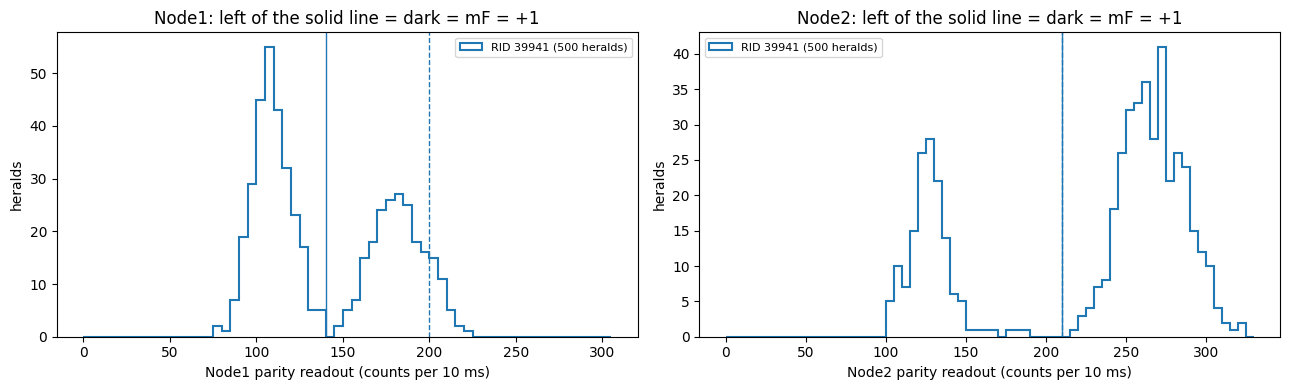

,RID,herald class,heralds,Node1 mF=+1 fraction,Node2 mF=+1 fraction
0,39941,Psi+,203,0.562,0.281
1,39941,Psi-,205,0.566,0.307
2,39941,same pol,92,0.576,0.272


In [14]:
if not runs: print('no files selected')
else:
    fig, axes = plt.subplots(1, 2, figsize=(13, 4))
    for ax, node in zip(axes, NODES):
        everything = np.concatenate([run[f'counts_{node}'][run['keep']] for run in runs])
        top = max(float(np.max(everything)) if len(everything) else 0.0, 300.0)
        bins = np.arange(0, top+10, 5)
        for k, run in enumerate(runs):
            exposure = float(run['t_alternating_RO_exposure'])
            ax.hist(run[f'counts_{node}'][run['keep']], bins=bins, histtype='step', lw=1.5, color=file_color(k),
                    label=f"RID {run['rid']} ({int(run['keep'].sum())} heralds)")
            ax.axvline(run[f'threshold_{node}']*exposure, color=file_color(k), ls='-', lw=1)
            ax.axvline(float(run[f'alternating_shot_threshold_{node}'])*exposure, color=file_color(k), ls='--', lw=1)
        ax.set_xlabel(f'{node} parity readout (counts per {exposure*1e3:g} ms)')
        ax.set_ylabel('heralds')
        ax.set_title(f'{node}: left of the solid line = dark = mF = +1')
        ax.legend(fontsize=8)
    plt.tight_layout()
    plt.show()

    rows = []
    for run in runs:
        for herald_class in ['Psi+', 'Psi-', 'same pol']:
            selected = run['keep'] & (run['herald_class'] == herald_class)
            row = {'RID': run['rid'], 'herald class': herald_class, 'heralds': int(selected.sum())}
            for node in NODES:
                row[f'{node} mF=+1 fraction'] = f"{np.mean(run[f'plus_{node}'][selected]):.3f}" if selected.any() else ''
            rows.append(row)
    display(pd.DataFrame(rows))

### A2. Thresholds from a per-node retention run
Two_nodes_alternating_retention_experiment uses the parity experiment's readout (two_node_alternating_windows) for both of its shots: the first after loading, the second after a FORT drop. Run it with t_FORT_drop 10 us on both nodes, as in RID 39936, so that the second shot holds both levels. For each node this fits two Gaussians to all its shots, prints the dark and bright levels, and gives the threshold that misclassifies the fewest shots (dark and bright weighted equally). The selected files' parity readouts are drawn on top (black).

RID 39936 Node1: dark 106 +- 11, bright 183 +- 14 counts; threshold 140 counts = 14023 counts/s, 0.08% misclassified (fit); RO1 bright 0.857, retention 0.689
RID 39936 Node2: dark 117 +- 10, bright 264 +- 20 counts; threshold 167 counts = 16676 counts/s, 0.00% misclassified (fit); RO1 bright 0.863, retention 0.683


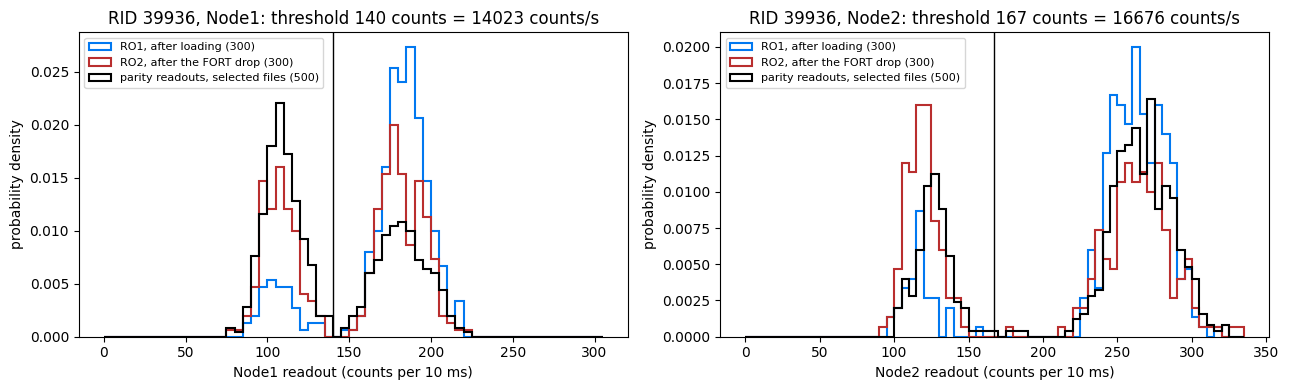


readout_thresholds = {'Node1': 14023.0, 'Node2': 16676.0}


In [15]:
### runs of Two_nodes_alternating_retention_experiment (RIDs from date_filters) to fit thresholds to; [] to skip
calibration_rids = [39936]


def two_gaussians(x, a1, m1, s1, a2, m2, s2):
    return a1*np.exp(-(x-m1)**2/(2*s1**2))+a2*np.exp(-(x-m2)**2/(2*s2**2))


def fit_levels(counts):
    """Dark and bright level of one node's readout (two Gaussians fitted to the
    histogram), and the threshold with the fewest misclassified shots, in counts."""
    counts = np.asarray(counts, dtype=float)
    histogram, edges = np.histogram(counts, bins=np.arange(0, counts.max()+10, 5))
    centers = 0.5*(edges[:-1]+edges[1:])
    low, high = np.percentile(counts, [10, 90])
    p, _ = curve_fit(two_gaussians, centers, histogram, p0=[histogram.max()/2, low, 15, histogram.max(), high, 25], maxfev=20000)
    a1, m1, s1, a2, m2, s2 = p
    if m1 > m2: a1, m1, s1, a2, m2, s2 = a2, m2, s2, a1, m1, s1
    s1, s2 = abs(s1), abs(s2)
    trial = np.arange(m1, m2, 0.5)
    ### mean of P(dark shot above) and P(bright shot below)
    misclassified = 0.5*(0.5*erfc((trial-m1)/(s1*np.sqrt(2)))+0.5*erfc((m2-trial)/(s2*np.sqrt(2))))
    best = int(np.argmin(misclassified))
    return {'dark': (m1, s1), 'bright': (m2, s2), 'threshold': float(trial[best]), 'misclassified': float(misclassified[best])}


calibration_files = {int(os.path.basename(p).split('-')[0]): p for p in ms_two_nodes_files(date_filters, experiment_functions=['Two_nodes_alternating_retention_experiment'], start_dir=results)}
suggested = {}
for rid in calibration_rids:
    if rid not in calibration_files:
        print(f"RID {rid}: no Two_nodes_alternating_retention_experiment file in {date_filters}")
        continue
    with h5py.File(calibration_files[rid], 'r') as f:
        d = f['datasets']
        exposure = float(d['t_alternating_RO_exposure'][()])
        shots = {node: {shot: np.ravel(np.asarray(d[f'AllSPCMs_alternating_{shot}_{node}'][()], dtype=float))[1:] for shot in ('RO1', 'RO2')} for node in NODES}
    fig, axes = plt.subplots(1, 2, figsize=(13, 4))
    for ax, node in zip(axes, NODES):
        RO1, RO2 = shots[node]['RO1'], shots[node]['RO2']
        levels = fit_levels(np.concatenate([RO1, RO2]))
        threshold = levels['threshold']
        bins = np.arange(0, max(RO1.max(), RO2.max(), 300)+10, 5)
        ax.hist(RO1, bins=bins, histtype='step', lw=1.5, color=color1, density=True, label=f'RO1, after loading ({len(RO1)})')
        ax.hist(RO2, bins=bins, histtype='step', lw=1.5, color=color2, density=True, label=f'RO2, after the FORT drop ({len(RO2)})')
        parity_counts = np.concatenate([run[f'counts_{node}'][run['keep']] for run in runs]) if runs else np.array([])
        if len(parity_counts): ax.hist(parity_counts, bins=bins, histtype='step', lw=1.5, color='k', density=True, label=f'parity readouts, selected files ({len(parity_counts)})')
        ax.axvline(threshold, color='k', ls='-', lw=1)
        ax.set_xlabel(f'{node} readout (counts per {exposure*1e3:g} ms)')
        ax.set_ylabel('probability density')
        ax.set_title(f"RID {rid}, {node}: threshold {threshold:.0f} counts = {threshold/exposure:.0f} counts/s")
        ax.legend(fontsize=8)
        RO1_bright = RO1 > threshold
        print(f"RID {rid} {node}: dark {levels['dark'][0]:.0f} +- {levels['dark'][1]:.0f}, bright {levels['bright'][0]:.0f} +- {levels['bright'][1]:.0f} counts; "
              f"threshold {threshold:.0f} counts = {threshold/exposure:.0f} counts/s, {levels['misclassified']:.2%} misclassified (fit); "
              f"RO1 bright {np.mean(RO1_bright):.3f}, retention {np.sum(RO1_bright & (RO2 > threshold))/max(np.sum(RO1_bright), 1):.3f}")
        suggested.setdefault(node, []).append(threshold/exposure)
    plt.tight_layout()
    plt.show()
if suggested:
    print("\nreadout_thresholds = {" + ", ".join(f"'{node}': {np.mean(values):.0f}.0" for node, values in suggested.items()) + "}")

## B. Heralds
For each file: heralds per scan point by detector pair; the Bell-state classes per point; the time between the two clicks (max_click_separation_ns cuts on it); and the click times after t1.

,point,target_780_HWP_Node1,target_780_HWP_Node2,heralds,H1V2,V1H2,H1V1,H2V2,H1H2,V1V2,other,kept
0,0,0.0,0.0,50,9,10,11,7,9,4,0,50
1,1,10.0,10.0,50,14,10,12,8,2,4,0,50
2,2,20.0,20.0,50,6,11,15,11,3,4,0,50
3,3,30.0,30.0,50,10,8,13,9,4,6,0,50
4,4,40.0,40.0,50,12,5,11,11,6,5,0,50
5,5,50.0,50.0,50,12,12,9,8,6,3,0,50
6,6,60.0,60.0,50,8,15,7,9,6,5,0,50
7,7,70.0,70.0,50,10,10,9,9,7,5,0,50
8,8,80.0,80.0,50,13,8,11,13,3,2,0,50
9,9,90.0,90.0,50,13,9,10,10,4,4,0,50


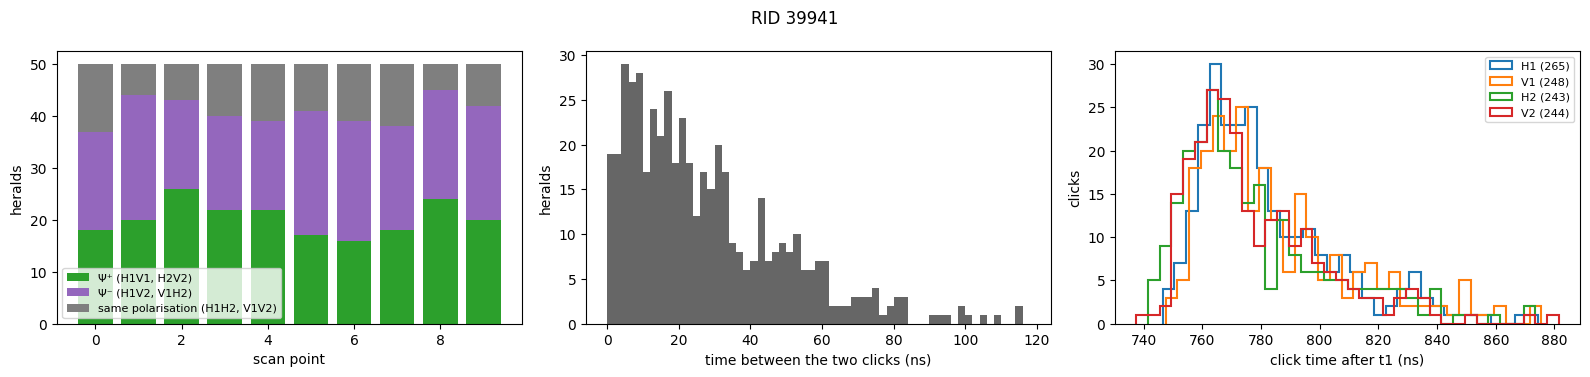

In [16]:
for k, run in enumerate(runs):
    display(HTML(f"<b style='font-size:16px;'>{run['date']} - RID {run['rid']}: {run['n_heralds']} heralds, {run['basis']}</b>"))
    rows = []
    for p in np.unique(run['point']):
        selected = run['point'] == p
        row = {'point': int(p)}
        if p < len(run['points']):
            row[run.get('scan_variable1_name') or 'variable1'] = run['points'][p][0]
            if run['points'][p][1] is not None: row[run['scan_variable2_name']] = run['points'][p][1]
        row['heralds'] = int(selected.sum())
        for pair in PAIRS: row[pair] = int(np.sum(selected & (run['pair'] == pair)))
        row['other'] = int(np.sum(selected & (run['herald_class'] == 'other')))
        row['kept'] = int(np.sum(selected & run['keep']))
        rows.append(row)
    display(pd.DataFrame(rows))

    fig, axes = plt.subplots(1, 3, figsize=(16, 3.8))
    points = np.unique(run['point'])
    bottom = np.zeros(len(points))
    for herald_class in ['Psi+', 'Psi-', 'same pol', 'other']:
        heights = np.array([np.sum((run['point'] == p) & (run['herald_class'] == herald_class)) for p in points])
        if heights.sum() == 0: continue
        axes[0].bar(points, heights, bottom=bottom, color=CLASS_COLORS[herald_class], label=CLASS_LABELS[herald_class])
        bottom = bottom+heights
    axes[0].set_xlabel('scan point')
    axes[0].set_ylabel('heralds')
    axes[0].legend(fontsize=8)

    separation = run['separation_ns'][np.isfinite(run['separation_ns'])]
    if len(separation):
        axes[1].hist(separation, bins=np.arange(0, separation.max()+5, 2), color='0.4')
    if max_click_separation_ns is not None: axes[1].axvline(max_click_separation_ns, color='r', ls='--')
    axes[1].set_xlabel('time between the two clicks (ns)')
    axes[1].set_ylabel('heralds')

    for name in SPCM_NAMES:
        times = run['click_ns'][name][np.isfinite(run['click_ns'][name])]
        if len(times): axes[2].hist(times, bins=np.arange(np.floor(times.min())-0.5, times.max()+5, 4), histtype='step', lw=1.5, label=f"{DETECTOR_LABELS[name]} ({len(times)})")
    axes[2].set_xlabel('click time after t1 (ns)')
    axes[2].set_ylabel('clicks')
    axes[2].legend(fontsize=8)
    fig.suptitle(f"RID {run['rid']}")
    plt.tight_layout()
    plt.show()

## C. Joint probabilities and fidelity
Per file and herald class, as in the single-node "Joint Probabilities and Fidelity" cells:
* the four joint probabilities against the scanned angle, each fitted with a sinusoid;
* the same (+1,+1 or −1,−1) and different (+1,−1 or −1,+1) parity sums, with their visibilities;
* **flat or oscillating**: a χ² test of P(same) against a constant (flat when p ≥ flat_p_value). A flat class is quoted from all its heralds pooled over the angles; every angle measures the same state there;
* for an oscillating class, the fidelity at the two extremes of the fitted P(same): the correlated one (maximum) and the anticorrelated one (minimum), each with the four fitted probabilities and its own target. The single-node θ* is the larger of these two, and taking the larger biases the number upward, so both are shown;
* θ†, the angle where the measured points separate most, as in the single-node notebook. At about 20–25 heralds per angle it is the maximum over noisy points: biased high and often 1.000. It is shown but never used as a headline.

Changes to the single-node method, needed at these statistics:
* **Fits.** The fits are parametrised by their low and high levels, both within 0–1, so the visibility |high − low|/(high + low) cannot exceed 1. The first pass is weighted with add-one errors. Two more passes are weighted with the binomial error of the fitted curve itself, so points that fluctuated towards 0 or 1 do not inflate the amplitude.
* **Errors from counts** (pooled, θ†) are the spread over Dirichlet(k+1) draws of the four counts. They stay finite when a count is 0.
* **Z reused for X.** Without an X-basis file the Z values are reused for the X terms, as in the single-node notebook: an estimate that assumes the X contrast equals the Z one, not a bound. Its error is propagated through the combined expression; the single-node notebook adds the X terms as if they were independent. Section E combines a Z and an X file.

Plotted probabilities are k/N with errors √(p(1−p)/N), p = (k+1)/(N+2). A fit needs at least 5 angles.

#### Helper functions

In [17]:
# ============================================================
# Fidelity
# ============================================================
from scipy.stats import chi2 as chi2_distribution

COMBINATIONS = [(True, True), (True, False), (False, True), (False, False)]  ### (Node1 mF=+1, Node2 mF=+1)
COMBINATION_LABELS = ['N1 +1, N2 +1', 'N1 +1, N2 −1', 'N1 −1, N2 +1', 'N1 −1, N2 −1']
COMBINATION_KEYS = ['+1,+1', '+1,-1', '-1,+1', '-1,-1']  ### the keys of section E
### (Z correlated, X correlated) -> the Bell state a bound is for
TARGET_STATES = {(True, True): 'Φ⁺', (True, False): 'Φ⁻', (False, True): 'Ψ⁺', (False, False): 'Ψ⁻'}


def fidelity_lower_bound(values_Z, errors_Z, values_X=None, errors_X=None, correlated=True, correlated_X=None):
    """
    Probability order (Node1, Node2), in Z and in X:
        values = [P(+1,+1), P(+1,-1), P(-1,+1), P(-1,-1)]

    The single-node bound with the photon replaced by Node2's atom:
        correlated target:      F >= (a + d - 2 sqrt(bc) + X term)/2
        anticorrelated target:  F >= (b + c - 2 sqrt(ad) + X term)/2
        X term = e + h - f - g if correlated_X, else f + g - e - h
    correlated is the target's Z correlation and correlated_X its X correlation
    (None: as Z); TARGET_STATES names the four combinations.

    If values_X and errors_X are not provided, the Z probability values are
    also used for the X-basis terms, as in the single-node notebook (an
    estimate that assumes the X contrast equals the Z one), and the error is
    propagated through the combined expression. With X values, the Z and X
    errors add as independent, which is the single-node formula. A square root
    of a zero product gets no error, as in the single-node sqrt_prod_sigma2.
    """
    reuse = values_X is None
    values_X = values_Z if reuse else values_X
    errors_X = errors_Z if errors_X is None else errors_X
    correlated_X = correlated if correlated_X is None else correlated_X

    a, b, c, d = map(float, values_Z)
    e, f, g, h = map(float, values_X)
    errors_Z = np.asarray(errors_Z, dtype=float)
    errors_X = np.asarray(errors_X, dtype=float)

    def sqrt_term(p, q):
        """sqrt(pq) and its derivatives by p and q"""
        if p <= 0 or q <= 0:
            return np.sqrt(max(p*q, 0.0)), 0.0, 0.0
        return np.sqrt(p*q), 0.5*np.sqrt(q/p), 0.5*np.sqrt(p/q)

    if correlated:
        root, d_first, d_second = sqrt_term(b, c)
        z_term = a + d - 2.0*root
        gradient_Z = np.array([1.0, -2.0*d_first, -2.0*d_second, 1.0])
    else:
        root, d_first, d_second = sqrt_term(a, d)
        z_term = b + c - 2.0*root
        gradient_Z = np.array([-2.0*d_first, 1.0, 1.0, -2.0*d_second])
    sign = 1.0 if correlated_X else -1.0
    x_term = sign*(e + h - f - g)
    gradient_X = sign*np.array([1.0, -1.0, -1.0, 1.0])

    F_low = 0.5*(z_term + x_term)
    if reuse:
        var_F = np.sum((0.5*(gradient_Z + gradient_X))**2*errors_Z**2)
    else:
        var_F = 0.25*(np.sum(gradient_Z**2*errors_Z**2) + np.sum(gradient_X**2*errors_X**2))
    F_low_err = np.sqrt(max(float(var_F), 0.0))

    return F_low, F_low_err


def fidelity_estimate(P, correlated=True):
    """fidelity_lower_bound's value with the Z values reused for X, for rows of
    probabilities P (..., 4); vectorised for the Dirichlet draws."""
    a, b, c, d = np.moveaxis(np.asarray(P, dtype=float), -1, 0)
    if correlated:
        return 0.5*(a + d - 2*np.sqrt(np.maximum(b*c, 0)) + a + d - b - c)
    return 0.5*(b + c - 2*np.sqrt(np.maximum(a*d, 0)) + b + c - a - d)


def fidelity_from_counts(counts, correlated=True, draws=4000, seed=0):
    """The Z-reused-for-X fidelity of four counts (COMBINATIONS order): the value
    at k/N, and as its error the spread over Dirichlet(k+1) draws, which stays
    finite when a count is 0."""
    counts = np.asarray(counts, dtype=float)
    if counts.sum() <= 0:
        return np.nan, np.nan
    value = float(fidelity_estimate(counts/counts.sum(), correlated))
    samples = np.random.default_rng(seed).dirichlet(counts + 1, draws)
    return value, float(np.std(fidelity_estimate(samples, correlated)))


# ========================================================
# Analysis helper functions
# ========================================================

def joint_counts(run, mask):
    """The angles of the selected heralds, and at each the counts of the four
    (Node1, Node2) outcomes in COMBINATIONS order: shape (4, number of angles)."""
    x = run['x'][mask]
    plus_Node1, plus_Node2 = run['plus_Node1'][mask], run['plus_Node2'][mask]
    angles = np.unique(x)
    counts = np.array([[np.sum((x == angle) & (plus_Node1 == a) & (plus_Node2 == b)) for angle in angles] for a, b in COMBINATIONS], dtype=int).reshape(4, len(angles))
    return angles, counts


def joint_prob_and_err(counts, group=None):
    """Probability of the combinations in group (indices into COMBINATIONS; None:
    each one on its own) among all heralds at each angle, and its error."""
    counts = np.asarray(counts, dtype=float)
    total = counts.sum(axis=0)
    k = counts if group is None else counts[list(group)].sum(axis=0)[None, :]
    probability = np.full(k.shape, np.nan)
    np.divide(k, total, out=probability, where=total > 0)
    p_tilde = (k+1)/(total+2)
    probability_error = np.full(k.shape, np.nan)
    np.divide(np.sqrt(p_tilde*(1-p_tilde)), np.sqrt(total), out=probability_error, where=total > 0)
    return probability, probability_error


def level_sinusoid(theta_deg, low, high, frequency, phase):
    """low + (high - low)(1 + cos(f theta + phi))/2: between low and high, so a
    probability curve with both levels in [0, 1] stays in [0, 1]"""
    return low + (high - low)*0.5*(1 + np.cos(np.deg2rad(frequency*theta_deg) + phase))


def fit_sinusoid_prob(x, k, total, f0=4.0, df=0.5, min_points=5, passes=3):
    """Fit k/total against the angle x with level_sinusoid, frequency within f0 +- df.

    Started from eight phases (the best chi2 wins) with add-one errors
    sqrt(p~(1-p~)/N), p~ = (k+1)/(N+2); then refitted with the binomial error
    of the fitted curve itself (passes - 1 times). None with fewer than
    min_points angles or when no fit converges. 'reliable' is False when a
    parameter error is not finite or a level's error is above 0.5; such a fit
    gives no best angle and no fidelity.
    """
    x = np.asarray(x, dtype=float)
    k = np.asarray(k, dtype=float)
    total = np.asarray(total, dtype=float)
    valid = total > 0
    if valid.sum() < min_points:
        return None
    x, k, total = x[valid], k[valid], total[valid]
    probability = k/total
    p_tilde = (k + 1)/(total + 2)
    sigma = np.sqrt(p_tilde*(1 - p_tilde)/total)
    bounds = ([0.0, 0.0, f0 - df, -2*np.pi], [1.0, 1.0, f0 + df, 2*np.pi])

    best = None
    for phase_guess in np.linspace(-np.pi, np.pi, 8, endpoint=False):
        try:
            popt, pcov = curve_fit(level_sinusoid, x, probability, p0=[np.min(probability), np.max(probability), f0, phase_guess],
                                   sigma=sigma, absolute_sigma=True, bounds=bounds, maxfev=20000)
        except (RuntimeError, ValueError):
            continue
        chi2 = float(np.sum(((probability - level_sinusoid(x, *popt))/sigma)**2))
        if best is None or chi2 < best[2]:
            best = (popt, pcov, chi2)
    if best is None:
        return None
    popt, pcov, chi2 = best

    ### weights from the model, not from the points
    for _ in range(passes - 1):
        model = np.clip(level_sinusoid(x, *popt), 0.25/total, 1 - 0.25/total)
        sigma = np.sqrt(model*(1 - model)/total)
        try:
            popt, pcov = curve_fit(level_sinusoid, x, probability, p0=popt, sigma=sigma, absolute_sigma=True, bounds=bounds, maxfev=20000)
        except (RuntimeError, ValueError):
            break
        chi2 = float(np.sum(((probability - level_sinusoid(x, *popt))/sigma)**2))

    perr = np.sqrt(np.abs(np.diag(pcov)))
    low, high = popt[0], popt[1]
    if low + high > 0:
        visibility = abs(high - low)/(high + low)
        sign = 1.0 if high >= low else -1.0
        gradient = sign*np.array([-2*high, 2*low])/(high + low)**2  ### d/d low, d/d high
        visibility_error = float(np.sqrt(max(float(gradient @ pcov[:2, :2] @ gradient), 0.0)))
    else:
        visibility, visibility_error = np.nan, np.nan
    reliable = bool(np.all(np.isfinite(pcov)) and perr[0] <= 0.5 and perr[1] <= 0.5)

    x_fit = np.linspace(x.min(), x.max(), 400)
    y_fit = level_sinusoid(x_fit, *popt)

    return {'popt': popt, 'perr': perr, 'pcov': pcov, 'fit': (x_fit, y_fit), 'visibility': (visibility, visibility_error),
            'chi2_red': chi2/max(len(x) - 4, 1), 'reliable': reliable}


def fit_eval(theta_deg, popt):
    return np.clip(
        level_sinusoid(np.asarray(theta_deg, dtype=float), *popt),
        0.0,
        1.0,
    )


def prob_sigma_at_theta(theta_deg, popt, pcov):
    low, high, frequency, phase = popt
    argument = np.deg2rad(frequency*theta_deg) + phase

    jacobian = np.array([
        0.5*(1 - np.cos(argument)),
        0.5*(1 + np.cos(argument)),
        -0.5*(high - low)*np.sin(argument)*np.pi/180.0*theta_deg,
        -0.5*(high - low)*np.sin(argument),
    ])

    return np.sqrt(max(float(jacobian@pcov@jacobian), 0.0))


def analyse(run, herald_class, group_value=None, frequency=None, flat_p_value=0.01):
    """Everything C shows for one herald class of one run (and one value of a
    grid scan's second variable): counts, the four joint probabilities and the
    two parity sums with their fits, flat or oscillating, the pooled fidelity,
    the fidelity at both fitted extremes, and the data-selected angle."""
    mask = run['keep'] & (run['herald_class'] == herald_class)
    if run['group'] is not None:
        mask = mask & (run['group'] == group_value)
    angles, counts = joint_counts(run, mask)
    f0 = float(frequency) if frequency is not None else run['fit_frequency_auto']
    result = {'class': herald_class, 'group': group_value, 'n': int(mask.sum()), 'angles': angles, 'counts': counts, 'f0': f0,
              'flat': None, 'p_flat': np.nan, 'extremes': {}, 'theta_data': np.nan, 'F_data': (np.nan, np.nan)}
    if result['n'] == 0:
        return result

    total = counts.sum(axis=0)
    probability, error = joint_prob_and_err(counts)
    result['p'], result['err'] = probability, error
    result['fits'] = [fit_sinusoid_prob(angles, counts[i], total, f0) for i in range(4)]
    for name, group in (('same', (0, 3)), ('different', (1, 2))):
        p, e = joint_prob_and_err(counts, group)
        result[name], result[f'{name}_err'] = p[0], e[0]
        result[f'fit_{name}'] = fit_sinusoid_prob(angles, counts[list(group)].sum(axis=0), total, f0)
    ### P(same) - P(different) = 2 P(same) - 1
    result['parity'], result['parity_err'] = 2*result['same'] - 1, 2*result['same_err']

    # ========================================================
    # Flat or oscillating: P(same) against a constant
    # ========================================================
    same_counts = counts[[0, 3]].sum(axis=0)
    s = same_counts.sum()/total.sum()
    if len(angles) >= 2:
        chi2_flat = float(np.sum((same_counts - total*s)**2/(total*s*(1 - s)))) if 0 < s < 1 else 0.0
        result['p_flat'] = float(chi2_distribution.sf(chi2_flat, len(angles) - 1))
        result['flat'] = bool(result['p_flat'] >= flat_p_value)

    ### every herald of the class, pooled over the angles
    pooled = counts.sum(axis=1)
    pooled_p, pooled_err = joint_prob_and_err(pooled[:, None])
    correlated_pooled = bool(pooled[0] + pooled[3] >= pooled[1] + pooled[2])
    result.update(pooled=pooled, pooled_p=pooled_p[:, 0], pooled_err=pooled_err[:, 0], correlated_pooled=correlated_pooled,
                  F_pooled=fidelity_from_counts(pooled, correlated_pooled))

    # ========================================================
    # Oscillating: the two extremes of the fitted P(same)
    # ========================================================
    fits_ok = (result['fit_same'] is not None and result['fit_same']['reliable']
               and all(fit is not None and fit['reliable'] for fit in result['fits']))
    if result['flat'] is False and fits_ok:
        theta_grid = np.linspace(float(angles.min()), float(angles.max()), 5001)
        y_same = fit_eval(theta_grid, result['fit_same']['popt'])
        for kind, theta in (('correlated', float(theta_grid[np.argmax(y_same)])), ('anticorrelated', float(theta_grid[np.argmin(y_same)]))):
            values = [float(fit_eval(theta, fit['popt'])) for fit in result['fits']]
            errors = [prob_sigma_at_theta(theta, fit['popt'], fit['pcov']) for fit in result['fits']]
            result['extremes'][kind] = {'theta': theta, 'values': values, 'errors': errors,
                                        'F': fidelity_lower_bound(values, errors, correlated=(kind == 'correlated'))}
    elif result['flat'] is False:
        result['no_extremes_reason'] = 'a fit is missing or unreliable (fewer than 5 angles, or too few heralds)'

    # ========================================================
    # Best angle from measured data: the maximum over noisy points, biased high
    # ========================================================
    p11, p12, p21, p22 = probability
    with np.errstate(invalid='ignore'):
        separation_correlated = p11 + p22 - 2*np.sqrt(p12*p21)
        separation_anticorrelated = p12 + p21 - 2*np.sqrt(p11*p22)
    correlated_data = bool(np.nanmax(separation_correlated) >= np.nanmax(separation_anticorrelated))
    separation = separation_correlated if correlated_data else separation_anticorrelated
    i = int(np.nanargmax(separation))
    result.update(theta_data=float(angles[i]), N_data=int(total[i]), values_data=[float(probability[j][i]) for j in range(4)],
                  errors_data=[float(error[j][i]) for j in range(4)], correlated_data=correlated_data,
                  F_data=fidelity_from_counts(counts[:, i], correlated_data))
    return result


def value_text(value_error):
    value, error = value_error
    return f"{value:.3f} ± {error:.3f}" if np.isfinite(value) else ''


def visibility_text(fit):
    if fit is None:
        return 'no fit'
    return f"{fit['visibility'][0]:.3f} ± {fit['visibility'][1]:.3f}" + ('' if fit['reliable'] else ' (unreliable fit)')


def flat_text(result):
    if result['flat'] is None:
        return 'single angle'
    return f"{'flat' if result['flat'] else 'oscillating'} (p = {result['p_flat']:.2g})"


def correlation_text(correlated):
    return 'correlated' if correlated else 'anticorrelated'


def paste_line(run, values, errors, correlated):
    """The four probabilities as section E takes them"""
    X = run['basis'] == 'X parity'
    entries = ', '.join(f"'{key}': [{value:.3f}, {error:.3f}]" for key, value, error in zip(COMBINATION_KEYS, values, errors))
    return f"{'P_X' if X else 'P_Z'} = {{{entries}}}; {'correlated_X' if X else 'correlated_Z'} = {bool(correlated)}"


def title_of(run, result):
    group = f", {run['group_name']} = {result['group']:g}" if result['group'] is not None else ''
    return f"RID {run['rid']}: {CLASS_LABELS[result['class']]}, {run['basis']}{group}"


# ========================================================
# Plotting helper functions
# ========================================================

def probability_ylim(*arrays):
    finite_values = []

    for array in arrays:
        array = np.asarray(array, dtype=float).ravel()
        finite_values.extend(array[np.isfinite(array)])

    if len(finite_values) == 0:
        return 1.0

    y_max = np.max(finite_values)

    return max(0.1, min(1.0, np.ceil((y_max - 1e-12)*10)/10))


def count_ylim(*arrays):
    finite_values = []

    for array in arrays:
        array = np.asarray(array, dtype=float).ravel()
        finite_values.extend(array[np.isfinite(array)])

    if len(finite_values) == 0:
        return 1.0

    y_max = np.max(finite_values)

    if y_max <= 10:
        step = 1
    elif y_max <= 100:
        step = 10
    elif y_max <= 1000:
        step = 100
    else:
        step = 10**np.floor(np.log10(y_max))

    return np.ceil((y_max - 1e-12)/step)*step


def plot_probability_subplot(ax, x, curves, title, xlabel):
    """curves: (probability, error, fit or None, pooled level or None, label, color)
    per curve; the pooled level is drawn dashed"""
    tops = []
    for y, err, fit, level, label, color in curves:
        ax.errorbar(x, y, yerr=err, fmt="o", markersize=5, capsize=3, color=color, label=label)
        tops.append(np.asarray(y) + np.asarray(err))
        if fit is not None:
            ax.plot(fit['fit'][0], fit['fit'][1], "-", linewidth=2, color=color)
            tops.append(fit['fit'][1])
        if level is not None:
            ax.axhline(level, ls='--', lw=1.5, color=color)

    ax.set_xlabel(xlabel)
    ax.set_ylabel("Joint probability")
    ax.set_title(title)
    ax.set_ylim(0, probability_ylim(*tops))
    ax.legend(fontsize=9)
    ax.grid(False)


def plot_bar_subplot(ax, labels, values, errors, title):
    x_positions = np.arange(len(labels))
    values = np.asarray(values, dtype=float)
    errors = np.asarray(errors, dtype=float)

    colors = [
        (*color1[:3], 1.0),
        (*color2[:3], 1.0),
        (*color1[:3], 0.6),
        (*color2[:3], 0.6),
    ]

    bars = ax.bar(
        x_positions,
        values,
        yerr=errors,
        capsize=5,
        color=colors,
        edgecolor="none",
        linewidth=0,
    )

    y_max = probability_ylim(values + errors)

    ax.set_xticks(x_positions)
    ax.set_xticklabels(labels, rotation=15)
    ax.set_ylabel("Probability")
    ax.set_title(title)
    ax.set_ylim(0, y_max)
    ax.grid(False)

    for bar, value, error in zip(bars, values, errors):
        text_y = min(value + error + 0.015, y_max - 0.02)

        ax.text(
            bar.get_x() + bar.get_width()/2,
            text_y,
            f"{value:.3f} ± {error:.3f}",
            ha="center",
            va="bottom",
            fontsize=9,
        )


def plot_analysis(run, result):
    """The single-node 3 x 2 figure for one herald class of one run. An
    oscillating class gets its fits and the bars at both fitted extremes; a flat
    one its pooled levels (dashed), the pooled bars and the data-selected bars."""
    fig, axes = plt.subplots(3, 2, figsize=(9, 12))
    axes = axes.ravel()
    x, p, err = result['angles'], result['p'], result['err']
    oscillating = result['flat'] is False
    fits = result['fits'] if oscillating else [None]*4
    level = (lambda i: None) if oscillating else (lambda i: result['pooled_p'][i])

    plot_probability_subplot(axes[0], x, [(p[0], err[0], fits[0], level(0), "Node2 mF=+1", color1), (p[1], err[1], fits[1], level(1), "Node2 mF=−1", color2)],
                             "Joint probability, Node1 mF = +1", run['x_label'])
    plot_probability_subplot(axes[1], x, [(p[2], err[2], fits[2], level(2), "Node2 mF=+1", color1), (p[3], err[3], fits[3], level(3), "Node2 mF=−1", color2)],
                             "Joint probability, Node1 mF = −1", run['x_label'])
    pooled_same = None if oscillating else result['pooled_p'][0] + result['pooled_p'][3]
    plot_probability_subplot(axes[2], x, [(result['same'], result['same_err'], result['fit_same'] if oscillating else None, pooled_same, "P(+1,+1) + P(−1,−1)", "g"),
                                          (result['different'], result['different_err'], result['fit_different'] if oscillating else None,
                                           None if oscillating else 1 - pooled_same, "P(+1,−1) + P(−1,+1)", "m")],
                             f"Same and different parity: {flat_text(result)}", run['x_label'])

    counts = result['counts']
    axes[3].plot(x, counts[0] + counts[1], 'o-', label="Node1 mF=+1")
    axes[3].plot(x, counts[2] + counts[3], 'o-', label="Node1 mF=−1")
    axes[3].plot(x, counts.sum(axis=0), 'o-', label="Total")
    axes[3].set_xlabel(run['x_label'])
    axes[3].set_ylabel("Heralds")
    axes[3].set_title("Heralds of this class per angle")
    axes[3].set_ylim(0, count_ylim(counts.sum(axis=0)) + 5)
    axes[3].legend(fontsize=9)

    if result['extremes']:
        for ax, kind in zip(axes[4:], ('correlated', 'anticorrelated')):
            extreme = result['extremes'][kind]
            plot_bar_subplot(ax, COMBINATION_LABELS, extreme['values'], extreme['errors'],
                             f"Fitted {kind} extreme θ = {extreme['theta']:.2f}°\nF = {value_text(extreme['F'])}")
    else:
        plot_bar_subplot(axes[4], COMBINATION_LABELS, result['pooled_p'], result['pooled_err'],
                         f"All angles pooled (N={result['n']}), {correlation_text(result['correlated_pooled'])}\nF = {value_text(result['F_pooled'])}")
        plot_bar_subplot(axes[5], COMBINATION_LABELS, result['values_data'], result['errors_data'],
                         f"Measured θ† = {result['theta_data']:.2f}° (N={result['N_data']}), biased high\nF = {value_text(result['F_data'])}")

    fig.suptitle(title_of(run, result), fontsize=13)
    fig.tight_layout(rect=[0, 0, 1, 0.97])
    plt.show()
    plt.close(fig)


def print_analysis(run, result):
    print(f"{title_of(run, result)}: {result['n']} heralds at {len(result['angles'])} angle(s), fit frequency {result['f0']:g} ± 0.5, {flat_text(result)}")
    for label, fit in zip(COMBINATION_LABELS, result['fits']):
        print(f"    visibility ({label}): {visibility_text(fit)}")
    print(f"    visibility (same):      {visibility_text(result['fit_same'])}")
    print(f"    visibility (different): {visibility_text(result['fit_different'])}")
    if result['flat'] is not False:
        ### a flat class (or a single angle): every herald measured the same state
        quote = '  <- quote this: the class is flat' if result['flat'] else ''
        print(f"    all angles pooled (N={result['n']}): {correlation_text(result['correlated_pooled'])}, fidelity {value_text(result['F_pooled'])}{quote}")
        print("        " + paste_line(run, result['pooled_p'], result['pooled_err'], result['correlated_pooled']))
    for kind, extreme in result['extremes'].items():
        print(f"    fitted {kind} extreme θ = {extreme['theta']:.3f}°: fidelity {value_text(extreme['F'])}")
        print("        " + paste_line(run, extreme['values'], extreme['errors'], kind == 'correlated'))
    if result.get('no_extremes_reason'):
        print(f"    no fitted extremes: {result['no_extremes_reason']}")
    print(f"    data-selected θ† = {result['theta_data']:.3f}° (N={result['N_data']}): {correlation_text(result['correlated_data'])}, "
          f"fidelity {value_text(result['F_data'])} (maximum over the angles: biased high)")

#### Summary only
One row per file and herald class (and per value of a grid scan's second variable). Z parity comes first, then the rows are ordered by QWP angles. Below the table, P(same) − P(different) (⟨Z₁Z₂⟩ in the Z basis, ⟨X₁X₂⟩ in X) is plotted against the angle for every selected file, one panel per herald class: the fit for an oscillating class, a dashed line at the pooled value for a flat one.

,Parity,RID,File index,Comment,Herald,Group,QWP Node1,QWP Node2,t_MW_RF_pulse N1/N2 (us),t_start_MW_mapping_mu N1/N2,Heralds,Flat?,Visibility same,Visibility different,Pooled fidelity (flat),Correlated extreme,F (correlated extreme),Anticorrelated extreme,F (anticorrelated extreme),Data-selected θ† (biased high)
0,Z parity,39941,2,"Z parity, both HWPs np.arange(0,91,10) (RID 39...",Psi+,,75,210,0/0,10000/10000,203,flat (p = 0.2),0.111 ± 0.092,0.142 ± 0.117,0.174 ± 0.066 (correlated),,,,,"60.0°, N=16, F=0.531 ± 0.188"
1,Z parity,39941,2,"Z parity, both HWPs np.arange(0,91,10) (RID 39...",Psi-,,75,210,0/0,10000/10000,205,flat (p = 0.013),0.318 ± 0.090,0.404 ± 0.113,0.154 ± 0.067 (correlated),,,,,"20.0°, N=17, F=0.647 ± 0.180"


Best pooled fidelity (flat classes): RID 39941: Ψ⁺ (H1V1, H2V2), Z parity, correlated, F = 0.174 ± 0.066
(Each fidelity here reuses its own basis for the other one: an estimate until a Z and an X file are combined in E. Rows with fewer than 20 heralds are left out of the best lines, and the best of several numbers is itself a little high.)


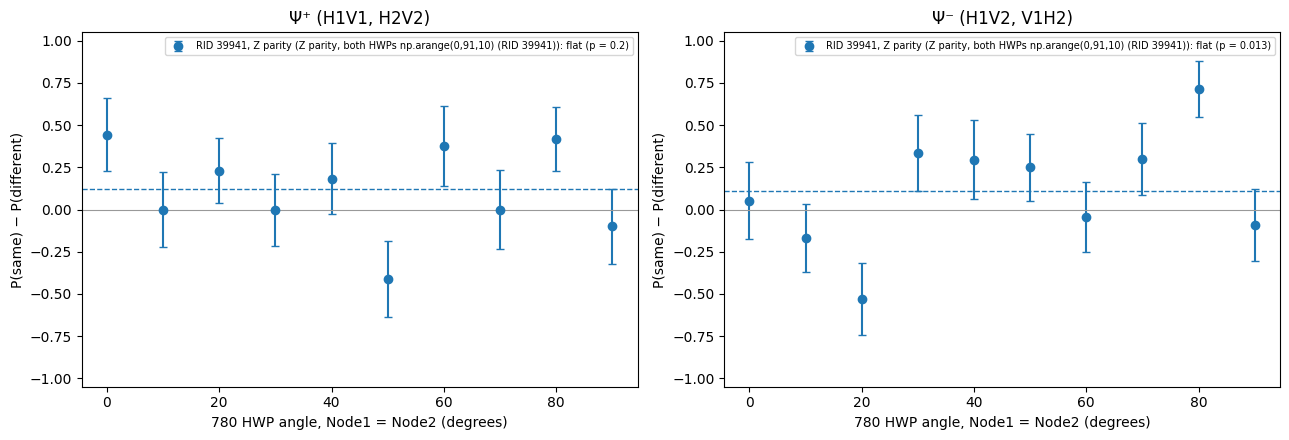

In [18]:
### rows with fewer heralds take no part in the 'best' lines
min_heralds_for_best = 20

summary_rows = []
best_fitted = None
best_pooled = None

for run in runs:
    for herald_class in herald_classes:
        for group_value in run['group_values']:
            result = analyse(run, herald_class, group_value, fit_frequency, flat_p_value)
            if result['n'] == 0:
                continue
            extremes = result['extremes']
            row = {
                "Parity": run['basis'],
                "RID": run['rid'],
                "File index": run['file_index'],
                "Comment": run['comment'],
                "Herald": herald_class,
                "Group": '' if group_value is None else f"{run['group_name']} = {group_value:g}",
                "QWP Node1": ', '.join(f'{v:g}' for v in np.unique(run['angles']['QWP_Node1'])),
                "QWP Node2": ', '.join(f'{v:g}' for v in np.unique(run['angles']['QWP_Node2'])),
                "t_MW_RF_pulse N1/N2 (us)": f"{float(run.get('t_MW_RF_pulse_Node1', 0.0))*1e6:g}/{float(run.get('t_MW_RF_pulse_Node2', 0.0))*1e6:g}",
                "t_start_MW_mapping_mu N1/N2": f"{run.get('t_start_MW_mapping_mu_Node1')}/{run.get('t_start_MW_mapping_mu_Node2')}",
                "Heralds": result['n'],
                "Flat?": flat_text(result),
                "Visibility same": visibility_text(result['fit_same']),
                "Visibility different": visibility_text(result['fit_different']),
                "Pooled fidelity (flat)": '' if result['flat'] is False else f"{value_text(result['F_pooled'])} ({correlation_text(result['correlated_pooled'])})",
                "Correlated extreme": f"{extremes['correlated']['theta']:.1f}°" if extremes else '',
                "F (correlated extreme)": value_text(extremes['correlated']['F']) if extremes else '',
                "Anticorrelated extreme": f"{extremes['anticorrelated']['theta']:.1f}°" if extremes else '',
                "F (anticorrelated extreme)": value_text(extremes['anticorrelated']['F']) if extremes else '',
                "Data-selected θ† (biased high)": f"{result['theta_data']:.1f}°, N={result['N_data']}, F={value_text(result['F_data'])}",
            }
            summary_rows.append(row)
            for kind, extreme in extremes.items():
                if result['n'] < min_heralds_for_best:
                    continue
                if best_fitted is None or extreme['F'][0] > best_fitted[2]['F'][0]:
                    best_fitted = (run, result, extreme, kind)
            if result['flat'] and result['n'] >= min_heralds_for_best and (best_pooled is None or result['F_pooled'][0] > best_pooled[1]['F_pooled'][0]):
                best_pooled = (run, result)

summary_df = pd.DataFrame(summary_rows)
if len(summary_df):
    summary_df["_parity_order"] = summary_df["Parity"].map(lambda basis: {'Z parity': 0, 'X parity': 1}.get(basis, 2))
    summary_df = summary_df.sort_values(["_parity_order", "QWP Node1", "QWP Node2", "RID", "Herald"], kind="stable").drop(columns="_parity_order").reset_index(drop=True)
display(summary_df)

if best_fitted is not None:
    run, result, extreme, kind = best_fitted
    print(f"\nBest fitted fidelity (oscillating classes, either extreme): {title_of(run, result)}, {kind} extreme θ = {extreme['theta']:.3f}°, F = {value_text(extreme['F'])}")
if best_pooled is not None:
    run, result = best_pooled
    print(f"Best pooled fidelity (flat classes): {title_of(run, result)}, {correlation_text(result['correlated_pooled'])}, F = {value_text(result['F_pooled'])}")
print("(Each fidelity here reuses its own basis for the other one: an estimate until a Z and an X file are combined in E. "
      f"Rows with fewer than {min_heralds_for_best} heralds are left out of the best lines, and the best of several numbers is itself a little high.)")


# ============================================================
# P(same) - P(different) against the angle, all selected files
# ============================================================
if runs:
    x_labels = sorted({run['x_label'] for run in runs})
    fig, axes = plt.subplots(1, len(herald_classes), figsize=(6.5*len(herald_classes), 4.5), squeeze=False)
    for ax, herald_class in zip(axes[0], herald_classes):
        j = 0
        for run in runs:
            for group_value in run['group_values']:
                result = analyse(run, herald_class, group_value, fit_frequency, flat_p_value)
                if result['n'] == 0:
                    continue
                color = file_color(j)
                j += 1
                label = f"RID {run['rid']}, {run['basis']}" + ('' if group_value is None else f", {group_value:g}") + (f" ({run['comment']})" if run['comment'] else '') + f": {flat_text(result)}"
                ax.errorbar(result['angles'], result['parity'], yerr=result['parity_err'], fmt='o', capsize=3, color=color, label=label)
                if result['flat'] is False and result['fit_same'] is not None:
                    x_fit, y_fit = result['fit_same']['fit']
                    ax.plot(x_fit, 2*y_fit - 1, '-', color=color)
                else:
                    ax.axhline(2*(result['pooled_p'][0] + result['pooled_p'][3]) - 1, ls='--', lw=1, color=color)
        ax.axhline(0, color='0.6', lw=0.8)
        ax.set_ylim(-1.05, 1.05)
        ax.set_xlabel(x_labels[0] if len(x_labels) == 1 else 'scanned angle (degrees); the files differ, see C file by file')
        ax.set_ylabel('P(same) − P(different)')
        ax.set_title(CLASS_LABELS[herald_class])
        ax.legend(fontsize=7)
    plt.tight_layout()
    plt.show()

#### Figures and analysis

File index: 2, RID: 39941
experiment: Two_nodes_atom_atom_parity_experiment
override Node1: {'n_excitation_attempts': 2, 'two_atom_threshold': 31000.0, 'target_780_QWP': 75.0, 't_OP_coil_relax_time': 1.5*ms, 't_MW_RF_pulse': 0.0}
override Node2: {'target_780_QWP': 210.0, 't_MW_RF_pulse': 0.0}

RID 39941: Ψ⁺ (H1V1, H2V2), Z parity: 203 heralds at 10 angle(s), fit frequency 8 ± 0.5, flat (p = 0.2)
    visibility (N1 +1, N2 +1): 0.526 ± 0.194
    visibility (N1 +1, N2 −1): 0.274 ± 0.127
    visibility (N1 −1, N2 +1): 0.973 ± 0.227
    visibility (N1 −1, N2 −1): 0.171 ± 0.134
    visibility (same):      0.111 ± 0.092
    visibility (different): 0.142 ± 0.117
    all angles pooled (N=203): correlated, fidelity 0.174 ± 0.066  <- quote this: the class is flat
        P_Z = {'+1,+1': [0.202, 0.028], '+1,-1': [0.360, 0.034], '-1,+1': [0.079, 0.019], '-1,-1': [0.360, 0.034]}; correlated_Z = True
    data-selected θ† = 60.000° (N=16): correlated, fidelity 0.531 ± 0.188 (maximum over the angles: b

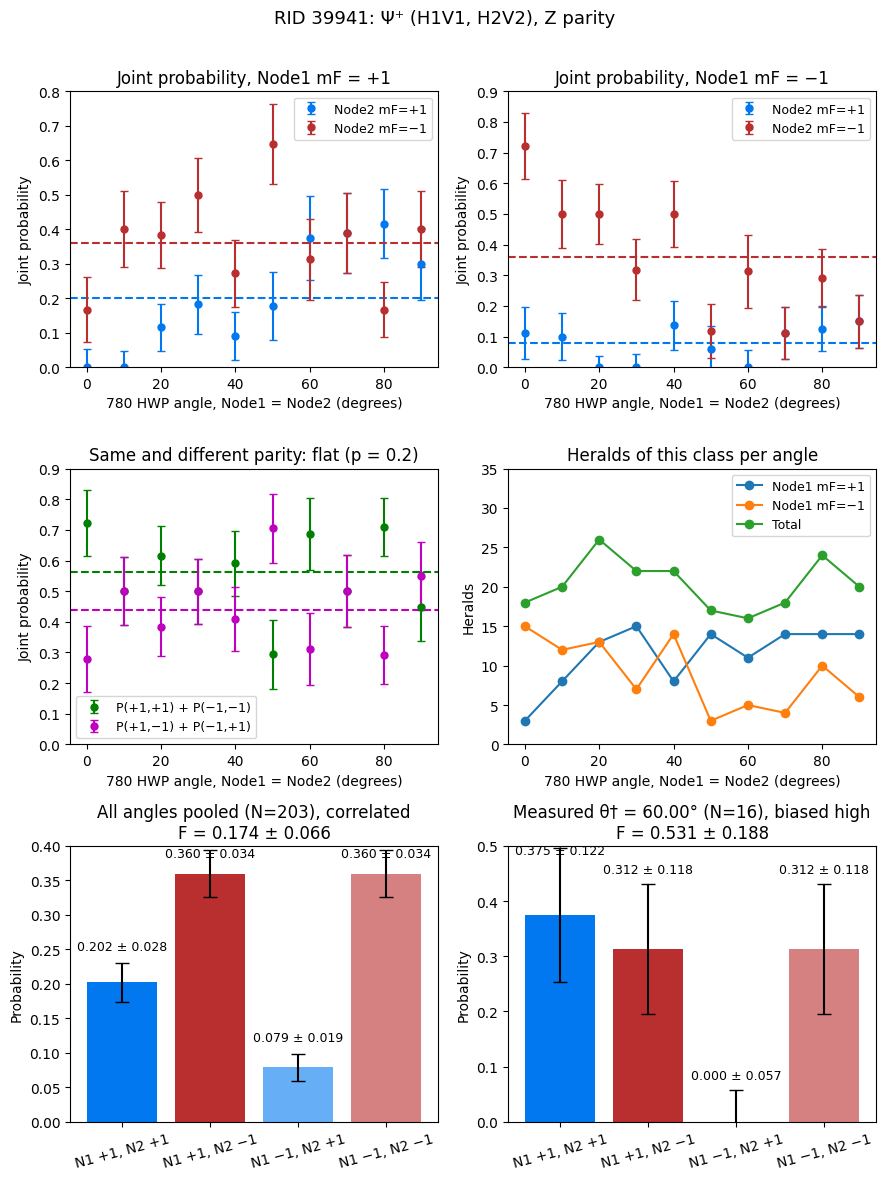


RID 39941: Ψ⁻ (H1V2, V1H2), Z parity: 205 heralds at 10 angle(s), fit frequency 8 ± 0.5, flat (p = 0.013)
    visibility (N1 +1, N2 +1): 0.519 ± 0.163
    visibility (N1 +1, N2 −1): 0.385 ± 0.138
    visibility (N1 −1, N2 +1): 0.483 ± 0.296
    visibility (N1 −1, N2 −1): 0.375 ± 0.144
    visibility (same):      0.318 ± 0.090
    visibility (different): 0.404 ± 0.113
    all angles pooled (N=205): correlated, fidelity 0.154 ± 0.067  <- quote this: the class is flat
        P_Z = {'+1,+1': [0.215, 0.029], '+1,-1': [0.351, 0.033], '-1,+1': [0.093, 0.021], '-1,-1': [0.341, 0.033]}; correlated_Z = True
    data-selected θ† = 20.000° (N=17): anticorrelated, fidelity 0.647 ± 0.180 (maximum over the angles: biased high)


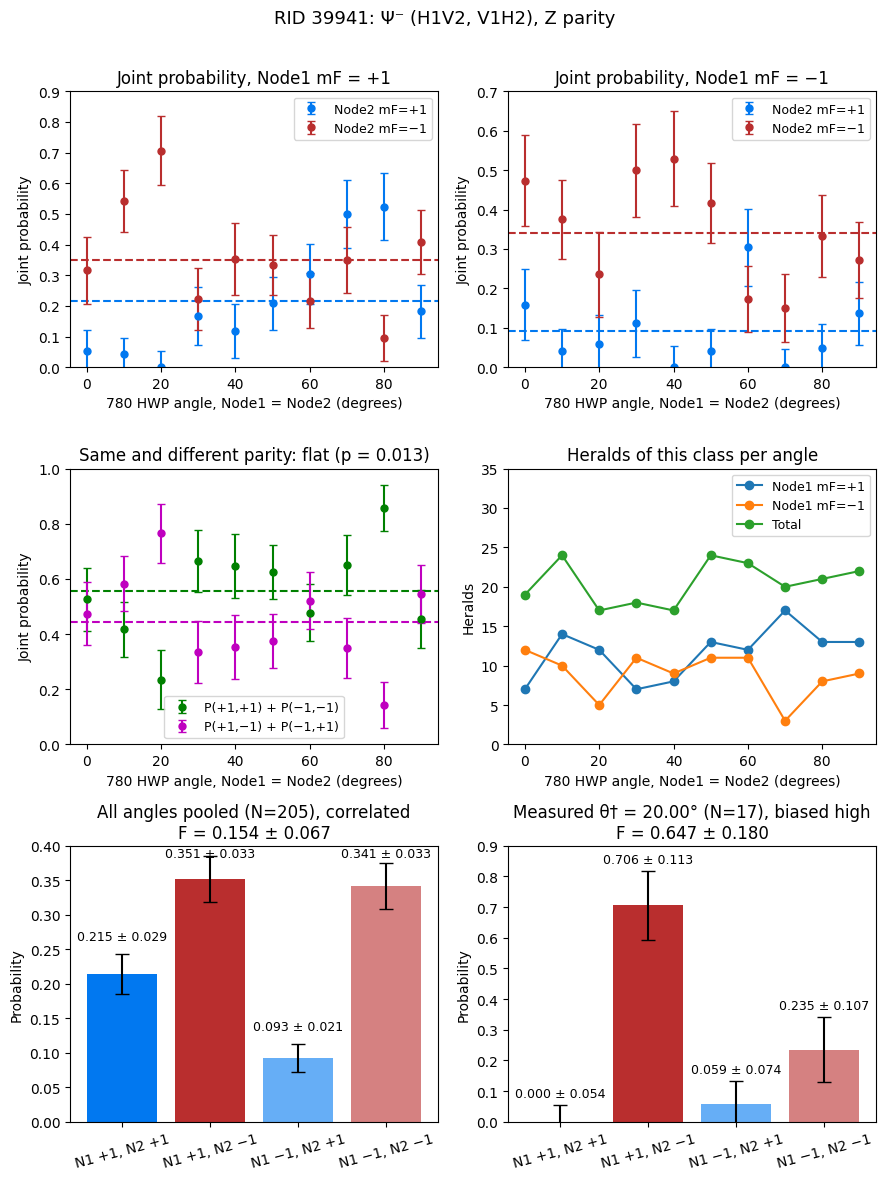

In [19]:
for run in runs:
    print("="*80)
    print(f"File index: {run['file_index']}, RID: {run['rid']}")
    print("experiment:", run['experiment_function'])
    ms_print_overrides(run['filename'])
    for herald_class in herald_classes:
        for group_value in run['group_values']:
            result = analyse(run, herald_class, group_value, fit_frequency, flat_p_value)
            if result['n'] == 0:
                print(f"{CLASS_LABELS[herald_class]}: no heralds")
                continue
            print()
            print_analysis(run, result)
            plot_analysis(run, result)

## D. Run summary and general analysis
### D1. Run summary
Per file:
* **Passes** through the excitation loop, heralded or not. Each pass starts from a fresh first-shot confirm.
* **Rate:** heralds per hour (from the first to the last load) and heralds per load.
* **Loading:** the MOT time of one load, and the time until the first shot passed (Atom_loading_time_first_shot_alive).
* **Excitation:** excitation cycles per pass, and photon events (attempts with any click) per cycle. As in the HOM notebook, the cycles include those run after an atom was lost, up to the next atom check.
* **Heralds per photon event.**
* **Underflows:** RTIO underflow retries and skipped points, with the sites when the GVS recorded them.

Retention (RO2/RO1) is left out: the second shot comes after the blow-away, so it measures the parity outcome, not survival. The magnetometer is not recorded in parity runs.

In [20]:
rows = {}
for run in runs:
    passes = run['passes']
    cycles = passes['n_excitation_cycles'] + 1
    photon_events = float(passes['n_photon_events'].sum())
    hours = run['wall_s']/3600
    n = run['n_heralds']
    loads = len(passes['Atom_loading_time'])
    rows[run['rid']] = {
        'basis': run['basis'],
        'complete points': f"{run['complete_points']}/{len(run['points'])}",
        'skipped points': len(run['skipped_points']),
        'heralds': n,
        **{f'  {CLASS_LABELS[c]}': int(np.sum(run['herald_class'] == c)) for c in CLASS_LABELS},
        'passes': len(cycles),
        'passes per herald': f"{len(cycles)/n:.1f}" if n else '',
        'hours, first to last load': f"{hours:.2f}",
        'heralds per hour': f"{n/hours:.0f}" if hours > 0 else '',
        'loads': loads,
        'heralds per load': f"{n/loads:.3f}" if loads else '',
        'MOT time per load (s)': f"{np.mean(passes['Atom_loading_time']):.3f}" if loads else '',
        'time until the first shot passed (s)': f"{np.mean(passes['Atom_loading_time_first_shot_alive']):.3f}" if len(passes['Atom_loading_time_first_shot_alive']) else '',
        'excitation cycles per pass': f"{np.mean(cycles):.1f}" if len(cycles) else '',
        'photon events per cycle': f"{photon_events/cycles.sum():.4f}" if cycles.sum() else '',
        'heralds per photon event': f"{n/photon_events:.4f}" if photon_events else '',
        'underflow retries': int(np.sum(run['underflow_retries'])),
    }
display(pd.DataFrame(rows))
for run in runs:
    if run['underflow_sites']:
        print(f"RID {run['rid']} underflows:\n{run['underflow_sites']}")

,39941
basis,Z parity
complete points,10/10
skipped points,0
heralds,500
"Ψ⁺ (H1V1, H2V2)",203
"Ψ⁻ (H1V2, V1H2)",205
"same polarisation (H1H2, V1V2)",92
not two clicks,0
passes,13584
passes per herald,27.2


### D2. FORT monitors, normalised to their set points
One entry per feedback run (one per scan point), recorded with the FORT at its loading set point, files one after another, as in the HOM notebook (D4).

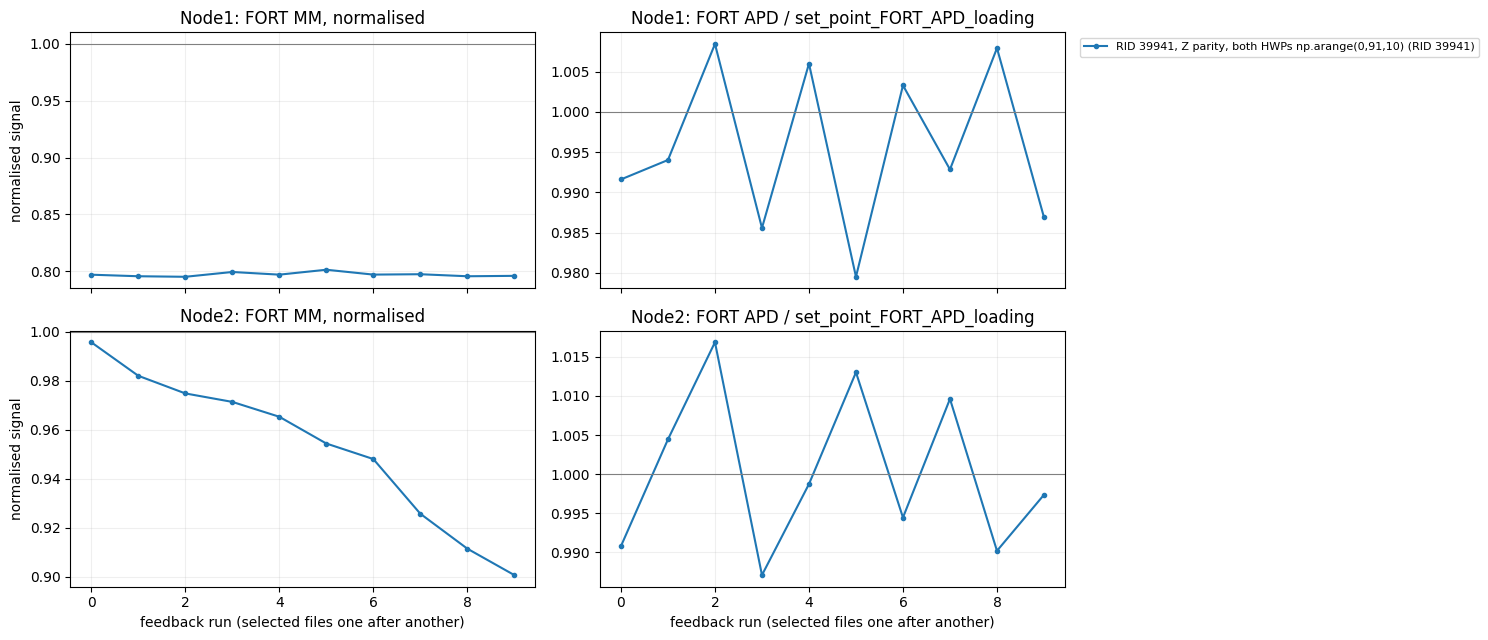

In [10]:
### FORT MM is normalised as in 2026_Single_Node_Microwaves:
###     FORT_MM_monitor / best_852_power_ref / (FORT_APD_monitor / set_point_FORT_APD_loading)
### and FORT APD by its loading set point, so both sit at ~1 when all is well.
if runs:
    fig, axes = plt.subplots(2, 2, figsize=(15, 6.5), sharex='col')
    for row, node in enumerate(NODES):
        for col, title in enumerate(['FORT MM, normalised', 'FORT APD / set_point_FORT_APD_loading']):
            ax = axes[row, col]
            offset = 0
            for k, run in enumerate(runs):
                MM, APD = run['monitors'][f'FORT_MM_monitor_{node}'], run['monitors'][f'FORT_APD_monitor_{node}']
                APD_norm = APD/float(run.get(f'set_point_FORT_APD_loading_{node}', np.nan))
                if col == 0:
                    y = MM/float(run.get(f'best_852_power_ref_{node}', np.nan))/APD_norm if len(MM) == len(APD) else np.array([])
                    if len(MM) == 0: print(f"RID {run['rid']}: no FORT monitor for {node} (enable_laser_feedback off?)")
                else:
                    y = APD_norm
                if len(y) == 0:
                    continue
                if offset > 0: ax.axvline(offset - 0.5, color='gray', ls='--', alpha=0.4)
                ax.plot(np.arange(offset, offset + len(y)), y, '.-', color=file_color(k), label=f"RID {run['rid']}" + (f", {run['comment']}" if run['comment'] else ''))
                offset += len(y)
            ax.axhline(1, color='gray', lw=0.8)
            ax.set_title(f'{node}: {title}')
            ax.grid(alpha=0.2)
        axes[row, 0].set_ylabel('normalised signal')
    for ax in axes[1]: ax.set_xlabel('feedback run (selected files one after another)')
    axes[0, 1].legend(bbox_to_anchor=(1.02, 1), loc='upper left', fontsize=8)
    plt.tight_layout()
    plt.show()

### D3. Atom loading time
Top: the MOT time of every load (Atom_loading_time; loads given up on, saved as 0, are left out). Bottom: per pass, the time from its first load until a first shot saw both atoms, rejected tries included (Atom_loading_time_first_shot_alive). Files one after another; dashed: each file's mean.

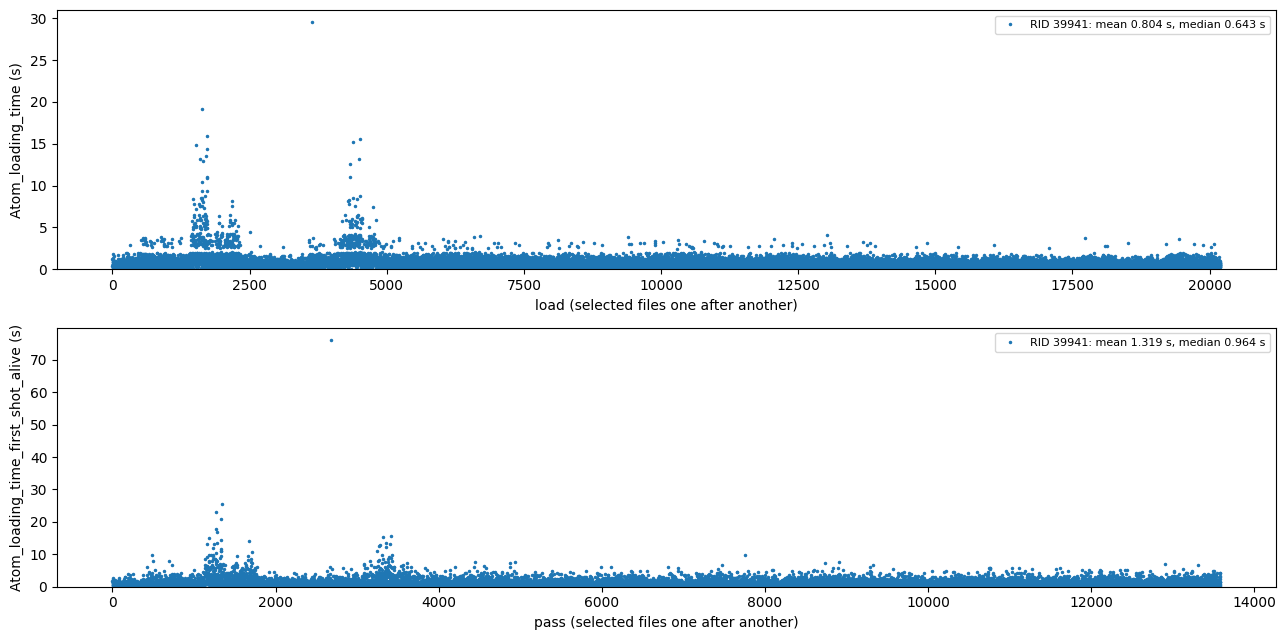

In [11]:
if runs:
    fig, axes = plt.subplots(2, 1, figsize=(13, 6.5))
    for ax, name, what in ((axes[0], 'Atom_loading_time', 'load'), (axes[1], 'Atom_loading_time_first_shot_alive', 'pass')):
        offset = 0
        for k, run in enumerate(runs):
            y = run['passes'][name]
            if len(y) == 0:
                continue
            if offset > 0: ax.axvline(offset - 0.5, color='gray', ls='--', alpha=0.4)
            ax.plot(np.arange(offset, offset + len(y)), y, '.', ms=3, color=file_color(k),
                    label=f"RID {run['rid']}: mean {np.mean(y):.3f} s, median {np.median(y):.3f} s")
            ax.hlines(np.mean(y), offset, offset + len(y) - 1, color=file_color(k), ls='--')
            offset += len(y)
        ax.set_xlabel(f'{what} (selected files one after another)')
        ax.set_ylabel(f'{name} (s)')
        ax.set_ylim(bottom=0)
        ax.legend(fontsize=8)
    plt.tight_layout()
    plt.show()

### D4. First shot
The joint first shot (AllSPCMs_RO1, both nodes together) that started each pass, in counts/s, with the run's two_atom_threshold (dashed). A pass starts only once a first shot is above it, so this shows the accepted shots: rejected tries are counted in n_first_shot_confirm_tries but not kept.

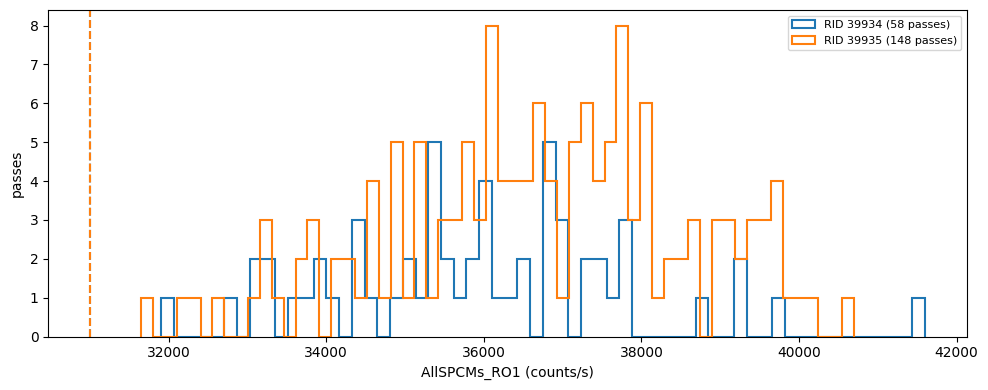

In [12]:
if runs:
    fig, ax = plt.subplots(figsize=(10, 4))
    for k, run in enumerate(runs):
        t_shot = run.get('t_SPCM_first_shot') or run.get('t_SPCM_first_shot_Node1')
        rates = run['passes']['AllSPCMs_RO1']/float(t_shot)
        if len(rates) == 0:
            continue
        ax.hist(rates, bins=60, histtype='step', lw=1.5, color=file_color(k), label=f"RID {run['rid']} ({len(rates)} passes)")
        if run.get('two_atom_threshold') is not None: ax.axvline(float(run['two_atom_threshold']), color=file_color(k), ls='--')
    ax.set_xlabel('AllSPCMs_RO1 (counts/s)')
    ax.set_ylabel('passes')
    ax.legend(fontsize=8)
    plt.tight_layout()
    plt.show()

## E. Fidelity from typed-in probabilities
To combine a Z-basis file with an X-basis file, type in the four joint probabilities of each, [value, error] in (Node1, Node2) order. C prints these as ready-to-paste P_Z / P_X lines.

correlated_Z and correlated_X give the target state's correlation in each basis (True: (+1,+1) and (−1,−1)); None reads it from the typed-in probabilities. (Z, X) = (correlated, correlated) is Φ⁺, (correlated, anticorrelated) Φ⁻, (anticorrelated, correlated) Ψ⁺, (anticorrelated, anticorrelated) Ψ⁻. With matched X mappings on both nodes, a Ψ⁻ herald gives Ψ⁻ and a Ψ⁺ herald Ψ⁺. In general the X sign also depends on the nodes' mapping phases (Larmor precession until each node's mapping, the two MW/RF pulses), which is why it is read from the X data. Without P_X the Z values are reused for X: an estimate, as in C.

In [13]:
P_Z = {'+1,+1': [0.05, 0.02], '+1,-1': [0.45, 0.05], '-1,+1': [0.45, 0.05], '-1,-1': [0.05, 0.02]}
P_X = None  ### or the same four from an X-basis file
correlated_Z = None  ### None: from P_Z
correlated_X = None  ### None: from P_X (as Z when there is no P_X)

order = ['+1,+1', '+1,-1', '-1,+1', '-1,-1']
if correlated_Z is None:
    correlated_Z = P_Z['+1,+1'][0] + P_Z['-1,-1'][0] >= P_Z['+1,-1'][0] + P_Z['-1,+1'][0]
if correlated_X is None and P_X is not None:
    correlated_X = P_X['+1,+1'][0] + P_X['-1,-1'][0] >= P_X['+1,-1'][0] + P_X['-1,+1'][0]
values_Z, errors_Z = [P_Z[k][0] for k in order], [P_Z[k][1] for k in order]
values_X = [P_X[k][0] for k in order] if P_X is not None else None
errors_X = [P_X[k][1] for k in order] if P_X is not None else None
F_low, F_low_err = fidelity_lower_bound(values_Z, errors_Z, values_X, errors_X, correlated=correlated_Z, correlated_X=correlated_X)
target = TARGET_STATES[(bool(correlated_Z), bool(correlated_Z if correlated_X is None else correlated_X))]
print(f"Fidelity lower bound to {target} = {F_low:.3f} ± {F_low_err:.3f}" + ("" if P_X is not None else " (Z values reused for X: an estimate)"))

Fidelity lower bound to Ψ⁻ = 0.800 ± 0.076 (Z values reused for X: an estimate)
